# $\text{TMA4215 Numerical Mathematics}\\ \text{Project: Numerical Integrators for Charged Particles}$

### Group members: Torgrim Frøystein, Ragurajh Kunasekaram & Walther Øren

In [44]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from IPython.display import display, Math  # for displaying LaTeX
import scienceplots  # for scientific plotting styles  # noqa: F401
from tqdm import tqdm  # progress bar
from numba import njit  # for JIT compilation
import sympy as sp  # symbolic mathematics
import time

%config InlineBackend.figure_formats = ['png']  # high-DPI raster plots in Jupyter
plt.rcParams["figure.dpi"] = 300
plt.rcParams["savefig.dpi"] = 300

In [42]:
plt.style.use(["science", "high-vis", "grid", "no-latex"])
plt.rcParams.update(
    {
        "figure.figsize": (12, 4),
        "lines.markersize": 5,
        "lines.linewidth": 1.5,
        "axes.labelsize": 14,
        "axes.titlesize": 15,
        "figure.titlesize": 18,
        "legend.fontsize": 14,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "figure.constrained_layout.use": True,
        "legend.frameon": True,
        "axes.titlepad": 10,
    }
)

# $3 \quad\text{Model problems}$

##  $3.1 \quad \text{2D charged particle}$

In [3]:
# symbolic Jacobian for A_2D
x1, x2, x3, r = sp.symbols("x1 x2 x3 r", real=True)
r_expr = sp.sqrt(x1**2 + x2**2)

A1_2D = -x2 * r_expr
A2_2D = x1 * r_expr
A3_2D = 0
A_vec_2D = sp.Rational(1, 3) * sp.Matrix([A1_2D, A2_2D, A3_2D])

Jacobian_A_2D_sym = sp.simplify(A_vec_2D.jacobian([x1, x2, x3]))
Jacobian_A_2D_display = Jacobian_A_2D_sym.subs(r_expr, r)

display(
    Math(r"\Large A'(x)_{\text{2D charged particle}}" + sp.latex(Jacobian_A_2D_display))
)

<IPython.core.display.Math object>

In [4]:
eps = 1e-14  # small regularization term


@njit
def B_2D(x):
    x1, x2, x3 = x
    r = np.sqrt(x1**2 + x2**2) + eps
    return np.array([0.0, 0.0, r])


@njit
def A_2D(x):
    x1, x2, x3 = x
    r = np.sqrt(x1**2 + x2**2) + eps
    return (1.0 / 3.0) * np.array([-x2 * r, x1 * r, 0.0])


@njit
def Jacobian_A_2D(x):
    x1, x2, x3 = x
    denom = np.sqrt(x1**2 + x2**2)
    if denom == 0.0:
        denom = eps
    r = denom + eps

    J = np.zeros((3, 3))
    J[0, 0] = -(1.0 / 3.0) * x2 * (x1 / denom)
    J[0, 1] = -(1.0 / 3.0) * (r + (x2**2) / denom)
    J[1, 0] = (1.0 / 3.0) * (r + (x1**2) / denom)
    J[1, 1] = (1.0 / 3.0) * x1 * (x2 / denom)
    return J


@njit
def U_2D(x):
    x1, x2, x3 = x
    r = np.sqrt(x1**2 + x2**2) + eps
    return 1.0 / (100.0 * r)


def U_2D_matrix(x_matrix):
    x1 = x_matrix[:, 0]
    x2 = x_matrix[:, 1]
    r = np.sqrt(x1**2 + x2**2) + eps
    return 1.0 / (100.0 * r)


@njit
def gradU_2D(x):
    x1, x2, x3 = x
    r3 = (x1**2 + x2**2 + eps) ** 1.5
    return -1.0 / 100.0 * np.array([x1 / r3, x2 / r3, 0.0])


# Initital conditions (IC)
iv_x_2D = np.array([0.0, 1.0, 0.1])
iv_v_2D = np.array([0.09, 0.05, 0.20])
ic_2D = np.hstack((iv_x_2D, iv_v_2D))
initial_energy_2D = 0.5 * np.dot(iv_v_2D, iv_v_2D) + U_2D(iv_x_2D)

## $3.2 \quad \text{Tokamak magnetic field}$

In [5]:
# symbolic Jacobian for A_Tokamak
A1_Tokamak = 0
A2_Tokamak = sp.Rational(1, 2) * (x1 - sp.log(r_expr + x1))
A3_Tokamak = -sp.Rational(1, 2) * (x3 * sp.atan2(x2, x1) + sp.log(x1**2 + x2**2))
A_vec_Tokamak = sp.Matrix([A1_Tokamak, A2_Tokamak, A3_Tokamak])

Jacobian_A_Tokamak_sym = sp.simplify(A_vec_Tokamak.jacobian([x1, x2, x3]))
Jacobian_A_Tokamak_display = Jacobian_A_Tokamak_sym.subs(r_expr, r)

display(Math(r"\Large A'(x)_{\text{Tokamak}}=" + sp.latex(Jacobian_A_Tokamak_display)))

<IPython.core.display.Math object>

In [6]:
@njit
def B_Tokamak(x):
    x1, x2, x3 = x
    r = np.sqrt(x1**2 + x2**2) + eps
    denom = 2.0 * r**2
    B_1 = -(2.0 * x2 + x1 * x3) / denom
    B_2 = (2.0 * x1 - x2 * x3) / denom
    B_3 = (r - 1.0) / (2.0 * r)
    return np.array([B_1, B_2, B_3])


@njit
def A_Tokamak(x):
    x1, x2, x3 = x
    r = np.sqrt(x1**2 + x2**2) + eps
    A_1 = 0.0
    A_2 = 0.5 * (x1 - np.log(r + x1 + eps))
    A_3 = -0.5 * (x3 * np.arctan2(x2, x1) + np.log(x1**2 + x2**2 + eps))
    return np.array([A_1, A_2, A_3])


@njit
def Jacobian_A_Tokamak(x):
    x1, x2, x3 = x
    denom = np.sqrt(x1**2 + x2**2)
    if denom == 0.0:
        denom = eps
    r = denom + eps

    J = np.zeros((3, 3))

    # Row 2 (A2)
    J[1, 0] = 1 / 2 - 1 / (2 * r)
    J[1, 1] = -x2 / (2 * r * (r + x1))

    # Row 3 (A3)
    J[2, 0] = (-x1 + x2 * x3 / 2) / r**2
    J[2, 1] = (-x1 * x3 / 2 - x2) / r**2
    J[2, 2] = -np.arctan2(x2, x1) / 2

    return J


@njit
def U_Tokamak(x):
    return 0.0


def U_Tokamak_matrix(x_matrix):
    return np.zeros(x_matrix.shape[0])


@njit
def gradU_Tokamak(x):
    return np.zeros(3)


# Initial conditions
iv_x_Tokamak = np.array([1.2, 0.0, 0.0])
iv_v_Tokamak = np.array([0, 4.816e-4, -2.059e-3])
ic_Tokamak = np.hstack((iv_x_Tokamak, iv_v_Tokamak))
initial_energy_Tokamak = 0.5 * np.dot(iv_v_Tokamak, iv_v_Tokamak) + U_Tokamak(
    iv_x_Tokamak
)

# $4 \quad \text{Methods to implement}$

### $\text{Energy function}$

In [7]:
def energy_equation(x, v, U):
    return 1 / 2 * (np.linalg.norm(v, axis=1)) ** 2 + U(x)

## $ 4.1 \quad \text{Boris Method}$

In [8]:
@njit
def t_func(B_n, h):
    return h / 2 * B_n


@njit
def s_func(t):
    return 2 * t / (1 + np.dot(t, t))


@njit
def v_minus(grad_U_n, h, v_n_minus_half):
    return v_n_minus_half - h / 2 * grad_U_n


@njit
def v_prime(v_minus, t):
    return v_minus + np.cross(v_minus, t)


@njit
def v_plus(v_minus, v_prime, s):
    return v_minus + np.cross(v_prime, s)


def initialize_v_minus_half(ic, A, B, gradU, h):
    # Initialize v at t=-h/2 for the first step of Boris method.
    def rhs(t, y):
        x = y[:3]
        v = y[3:]
        dxdt = v
        dvdt = np.cross(v, B(x)) - gradU(x)
        return np.hstack((dxdt, dvdt))

    sol = solve_ivp(rhs, t_span=(0, -h / 2), y0=ic)
    v_minus_half = sol.y[3:, -1]
    return v_minus_half

In [9]:
def boris_method(ic, t_start, t_end, h, U, B, A, gradU):
    num_steps = int((t_end - t_start) / h) + 1
    v_minus_half = initialize_v_minus_half(ic, A, B, gradU, h)
    x = np.zeros(shape=(num_steps, 3))
    v_half = np.zeros(shape=(num_steps, 3))
    x[0] = ic[:3]
    v_half[0] = v_minus_half

    with tqdm(
        total=num_steps - 1,
        desc="Boris Method",
        bar_format="{l_bar}{bar}| {n_fmt}/{total_fmt} [{elapsed}<{remaining}, {rate_fmt}]",
    ) as pbar:
        for i in range(num_steps - 1):
            grad_U_n = gradU(x[i])
            B_n = B(x[i])
            t1 = t_func(B_n, h)
            v_minus_temp = v_minus(grad_U_n=grad_U_n, h=h, v_n_minus_half=v_half[i])
            v_prime1 = v_prime(v_minus_temp, t1)
            v_plus1 = v_plus(v_minus_temp, v_prime1, s_func(t1))

            v_half[i + 1] = v_plus1 - h / 2 * grad_U_n
            x[i + 1] = x[i] + h * v_half[i + 1]

            pbar.update(1)

    return x, v_half


def v_integer_steps(v):
    # Convert half-step velocities to integer-step velocities.
    return 1 / 2 * (v[:-1] + v[1:])

# $4.2 \quad \text{Classical Runge-Kutta 4 on the extended system}$

In [10]:
@njit
def f(x, v, B, gradU):
    return np.cross(v, B(x)) - gradU(x)


def RK4_step(h, x_n, v_n, B, gradU):
    k1_v = h * f(x_n, v_n, B, gradU)
    k1_x = h * v_n
    k2_v = h * f(x_n + 1 / 2 * k1_x, v_n + 1 / 2 * k1_v, B, gradU)
    k2_x = h * (v_n + 1 / 2 * k1_v)
    k3_v = h * f(x_n + 1 / 2 * k2_x, v_n + 1 / 2 * k2_v, B, gradU)
    k3_x = h * (v_n + 1 / 2 * k2_v)
    k4_v = h * f(x_n + k3_x, v_n + k3_v, B, gradU)
    k4_x = h * (v_n + k3_v)

    v_n_plus_1 = v_n + 1 / 6 * (k1_v + 2 * k2_v + 2 * k3_v + k4_v)
    x_n_plus_1 = x_n + 1 / 6 * (k1_x + 2 * k2_x + 2 * k3_x + k4_x)

    return x_n_plus_1, v_n_plus_1


def RK4_solver(h, B, gradU, ic, t_start, t_end):
    num_steps = int((t_end - t_start) / h) + 1
    x = np.zeros(shape=(num_steps, 3))
    v = np.zeros(shape=(num_steps, 3))
    x[0] = ic[:3]
    v[0] = ic[3:]

    with tqdm(
        total=num_steps - 1,
        desc="RK4 Method",
        bar_format="{l_bar}{bar}| {n_fmt}/{total_fmt} [{elapsed}<{remaining}, {rate_fmt}]",
    ) as pbar:
        for i in range(num_steps - 1):
            x[i + 1], v[i + 1] = RK4_step(h, x[i], v[i], B, gradU)
            pbar.update(1)

    return x, v

## $4.3 \quad \text{Fourth-order symmetric multistep method (SMS)}$

In [11]:
def multistep_step(h, xn, A, A_jac, gradU, alphas, betas):
    """Fourth-order symmetric multistep method

    Args:
        h (float): step size
        xn (array[float], shape = (9,3)): x[0,:] corresponds to x_(n-4), x[8,:] to x_(n+4)
        A (function): Vector potential
        A_jac (function): Jacobian of A
        gradU (function): Gradient of U
        alphas (list) : parameters corresponding to alpha_(-4),...,alpha_(4)
        betas (list) : parameters corresponding to beta_(0) and beta_(1)

    Returns:
        x_(n+4)
    """

    def delta_x(j):
        idx = 4 + j
        return (1 / 12) * (
            xn[idx - 2, :] - 8 * xn[idx - 1, :] + 8 * xn[idx + 1, :] - xn[idx + 2, :]
        )

    def F(j):
        idx = 4 + j
        vj = delta_x(j) / h
        A_delta = (1 / (12 * h)) * (
            A(xn[idx - 2, :])
            - 8 * A(xn[idx - 1, :])
            + 8 * A(xn[idx + 1, :])
            - A(xn[idx + 2, :])
        )
        return A_jac(xn[idx, :]).T @ vj - A_delta - gradU(xn[idx, :])

    sum_term = np.dot(alphas[:8], xn[:8, :])
    rhs = h**2 * (betas[1] * (F(-1) + F(1)) + betas[0] * F(0))
    x_n_plus_4 = (rhs - sum_term) / alphas[8]

    return x_n_plus_4


def multistep_iterate(h, B, A, A_jac, gradU, ic, t_start, t_end):
    a1, a2, a3 = -0.7, 0.1, 0.9
    betas = [
        (
            1
            / 3
            * (
                20 * a1 * a2 * a3
                - 4 * (a1 * a2 + a1 * a3 + a2 * a3)
                - 28 * (a1 + a2 + a3)
                - 52
            )
        ),
        (
            1
            / 3
            * (
                2 * a1 * a2 * a3
                + 14 * (a1 * a2 + a1 * a3 + a2 * a3)
                + 26 * (a1 + a2 + a3)
                + 38
            )
        ),
    ]
    alphas = [1, -7 / 5, 9 / 25, 22 / 125, -34 / 125, 22 / 125, 9 / 25, -7 / 5, 1]

    num_steps = int((t_end - t_start) / h) + 1
    x = np.zeros(shape=(num_steps, 3))
    v = np.zeros(shape=(num_steps, 3))

    def rhs(t, y):
        x_state = y[:3]
        v_state = y[3:]
        dxdt = v_state
        dvdt = np.cross(v_state, B(x_state)) - gradU(x_state)
        return np.hstack((dxdt, dvdt))

    # Use solve_ivp to get initial steps
    t_eval = t_start + h * np.arange(8)
    sol = solve_ivp(
        rhs, t_span=(t_start, t_eval[-1]), y0=ic, t_eval=t_eval, rtol=1e-10, atol=1e-12
    )
    x[0:8, :] = sol.y[:3, :].T
    v[0:8, :] = sol.y[3:, :].T

    with tqdm(
        total=num_steps - 8,
        desc="Multistep Method",
        bar_format="{l_bar}{bar}| {n_fmt}/{total_fmt} [{elapsed}<{remaining}, {rate_fmt}]",
    ) as pbar:
        for n in range(4, num_steps - 4):
            xn_window = x[n - 4 : n + 5, :]

            x[n + 4, :] = multistep_step(
                h=h,
                xn=xn_window,
                A=A,
                A_jac=A_jac,
                gradU=gradU,
                alphas=alphas,
                betas=betas,
            )
            pbar.update(1)

    # Calculate velocities from positions
    for n in range(2, num_steps - 2):
        v[n, :] = (1 / (12 * h)) * (
            x[n - 2, :] - 8 * x[n - 1, :] + 8 * x[n + 1, :] - x[n + 2, :]
        )

    return x, v

# $5 \quad \text{Experiments \& deliverables} $

### $\text{Reference solution}$

In [12]:
def reference_solution(ic, A, B, gradU, h, t_start, t_end):
    last_eval_idx = [0]

    t_span = [t_start, t_end]
    num_steps = int((t_end - t_start) / h)
    t_eval = np.linspace(t_start, t_end, num_steps + 1)

    with tqdm(
        total=num_steps,
        desc="Reference Method",
        bar_format="{l_bar}{bar}| {n_fmt}/{total_fmt} [{elapsed}<{remaining}, {rate_fmt}]",
    ) as pbar:

        def rhs(t, y):
            x = y[:3]
            v = y[3:]
            dxdt = v
            dvdt = np.cross(v, B(x)) - gradU(x)

            # Update progress by completed t_eval steps
            idx = np.searchsorted(t_eval, t, side="right") - 1
            if idx > last_eval_idx[0]:
                pbar.update(idx - last_eval_idx[0])
                last_eval_idx[0] = idx

            return np.hstack((dxdt, dvdt))

        sol = solve_ivp(
            rhs, t_span=t_span, t_eval=t_eval, y0=ic, rtol=1e-12, atol=1e-12
        )

        # Ensure bar reaches total
        pbar.update(num_steps - last_eval_idx[0])

    return sol


def error(x_real, x_computed):
    return np.linalg.norm(x_real - x_computed, axis=1)


def energy_error(energy_initial, x, v, U_matrix_func):
    energy_solution = energy_equation(x, v, U_matrix_func)
    energy_initial_vec = np.empty(len(x))
    energy_initial_vec.fill(energy_initial)
    return np.abs(energy_solution - energy_initial)

## $\text{A. Plotting trajectories and error over long time}$

In [13]:
T = 1e5  # End time
h = 0.1  # Step size
num_steps = int((T - 0) / h)
t = np.linspace(0, T, num_steps + 1)  # t_0,t_1,...,t_N

### $\text{2D charged particle}$

In [14]:
# Compute reference solution for 2D charged particle
reference_solution_2D = reference_solution(
    ic_2D,
    A=A_2D,
    B=B_2D,
    gradU=gradU_2D,
    h=h,
    t_start=0,
    t_end=T,
)

Reference Method: 100%|██████████| 1000000/1000000 [04:43<00:00, 3531.90it/s]


In [15]:
x_reference_2D = np.transpose(reference_solution_2D.y[:3, :])
v_reference_2D = np.transpose(reference_solution_2D.y[3:, :])

In [16]:
# Boris
x_boris_2D, v_boris_2D = boris_method(
    ic=ic_2D,
    t_start=0,
    t_end=T,
    h=h,
    U=U_2D,
    B=B_2D,
    A=A_2D,
    gradU=gradU_2D,
)
v_boris_2D = v_integer_steps(v_boris_2D)
x_boris_2D = x_boris_2D[:-1, :]
t_boris_2D = t[:-1]

Boris Method: 100%|██████████| 1000000/1000000 [00:04<00:00, 212261.86it/s]


In [17]:
# Classical Runge-Kutta 4
x_RK4_2D, v_RK4_2D = RK4_solver(
    h=h,
    B=B_2D,
    gradU=gradU_2D,
    ic=ic_2D,
    t_start=0,
    t_end=T,
)

RK4 Method: 100%|██████████| 1000000/1000000 [00:28<00:00, 35303.82it/s]


In [18]:
# MS Method
x_MS_2D, v_MS_2D = multistep_iterate(
    h=h,
    B=B_2D,
    A=A_2D,
    A_jac=Jacobian_A_2D,
    gradU=gradU_2D,
    ic=ic_2D,
    t_start=0,
    t_end=T,
)

Multistep Method: 100%|██████████| 999993/999993 [00:32<00:00, 31119.24it/s]


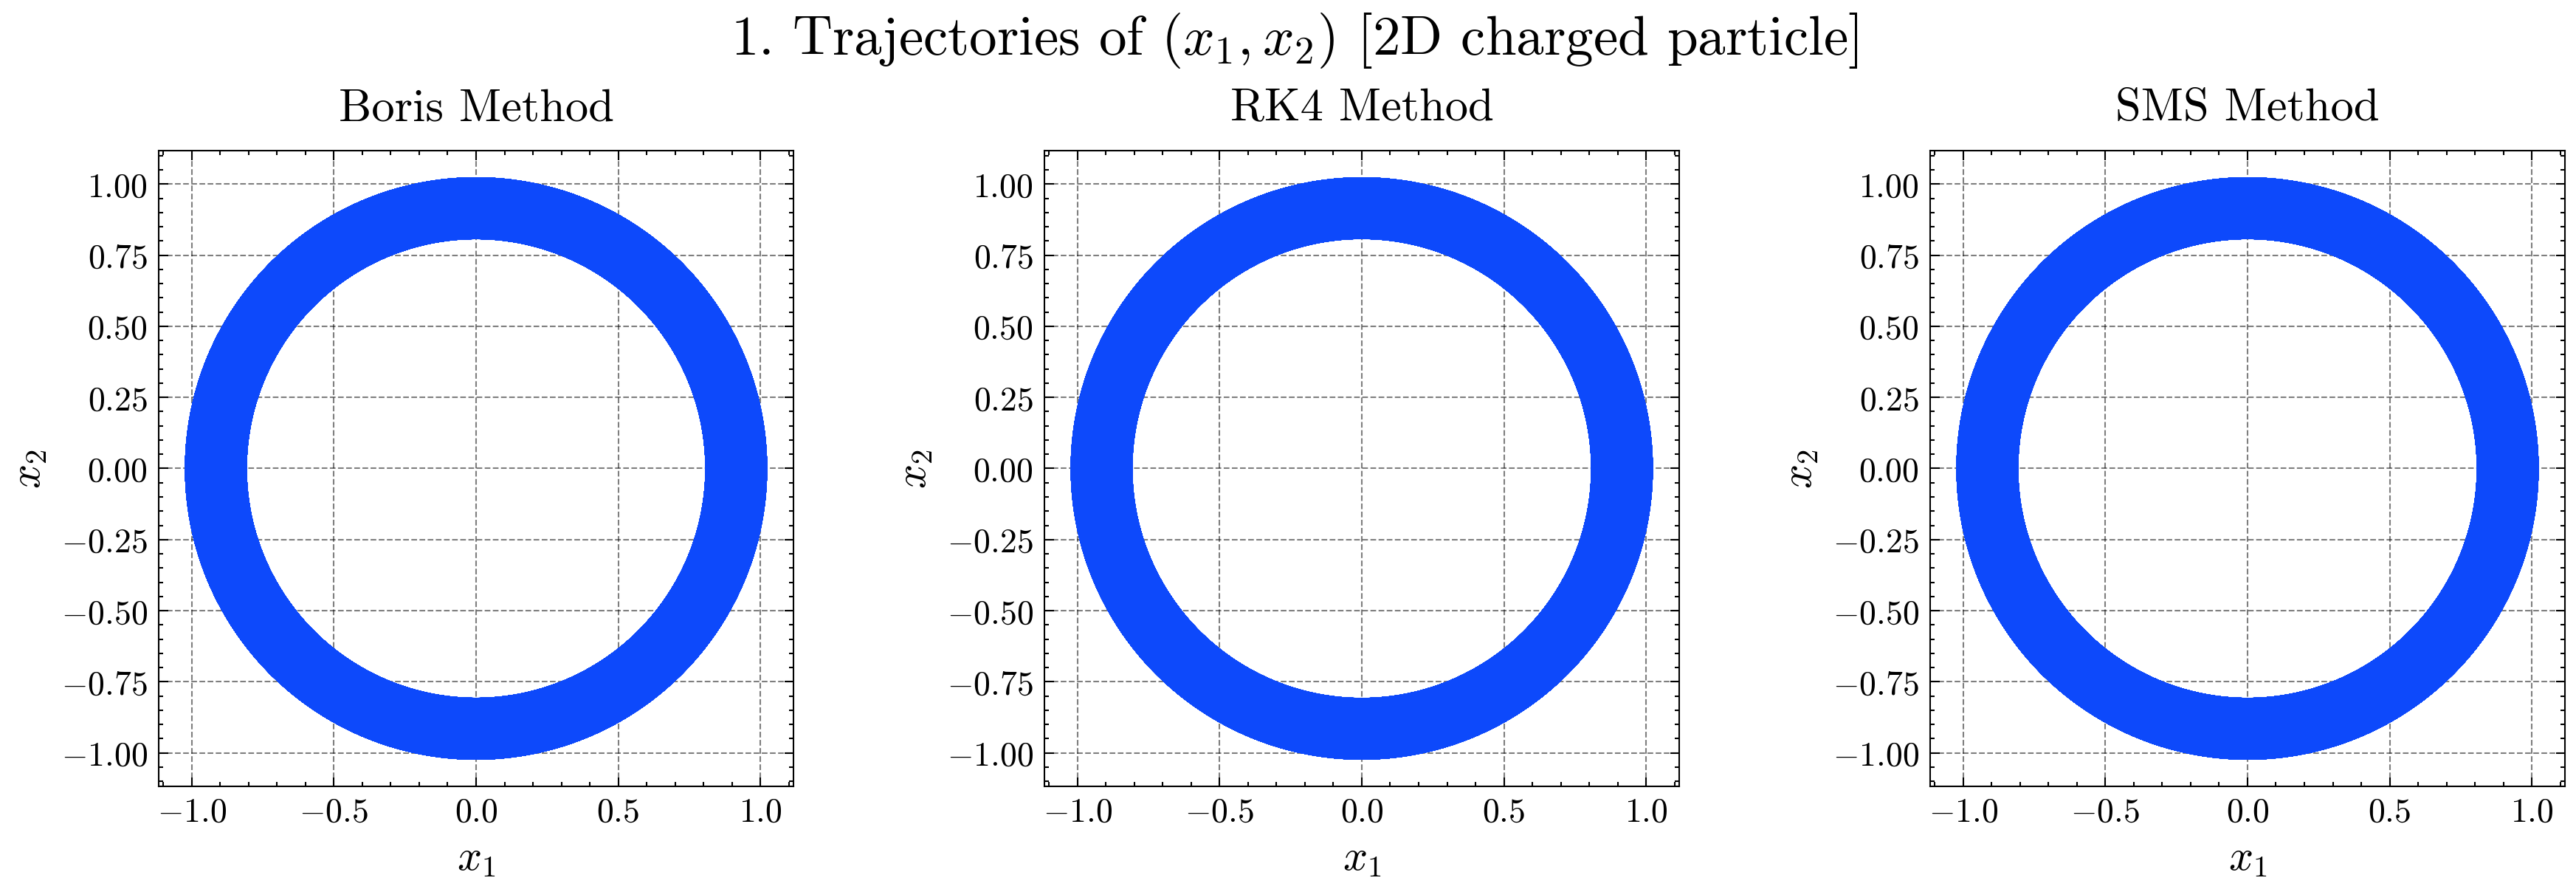

In [45]:
x1_boris_2D = x_boris_2D[:, 0]
x2_boris_2D = x_boris_2D[:, 1]

x1_RK4_2D = x_RK4_2D[:, 0]
x2_RK4_2D = x_RK4_2D[:, 1]

x1_MS_2D = x_MS_2D[:, 0]
x2_MS_2D = x_MS_2D[:, 1]


fig, axs = plt.subplots(1, 3, figsize=(12, 4))
fig.suptitle(r"1. Trajectories of $(x_1, x_2)$ [2D charged particle]")

# Boris method
axs[0].plot(
    x1_boris_2D,
    x2_boris_2D,
)
axs[0].set_title("Boris Method")
axs[0].set_xlabel(r"$x_1$")
axs[0].set_ylabel(r"$x_2$")
axs[0].set_aspect("equal", adjustable="box")

# RK4
axs[1].plot(
    x1_RK4_2D,
    x2_RK4_2D,
)
axs[1].set_title("RK4 Method")
axs[1].set_xlabel(r"$x_1$")
axs[1].set_ylabel(r"$x_2$")
axs[1].set_aspect("equal", adjustable="box")

# Fourth-order symmetric multistep method
axs[2].plot(
    x1_MS_2D,
    x2_MS_2D,
)
axs[2].set_title("SMS Method")
axs[2].set_xlabel(r"$x_1$")
axs[2].set_ylabel(r"$x_2$")
axs[2].set_aspect("equal", adjustable="box")
plt.show()

#### 1. Trajectories
All three numerical methods, Boris, RK4, and the Symmetric Multistep (SMS) method, produce identical circular trajectories in the $(x_1, x_2)$-plane.  
This agrees with the theoretical motion of a charged particle in a static magnetic field, which should move on a circular or helical path with approximately constant energy.  
The fact that the trajectories coincide indicates that the chosen step size $h = 0.1$ is sufficiently small to maintain accuracy for long-time integration up to $T = 10^5$.


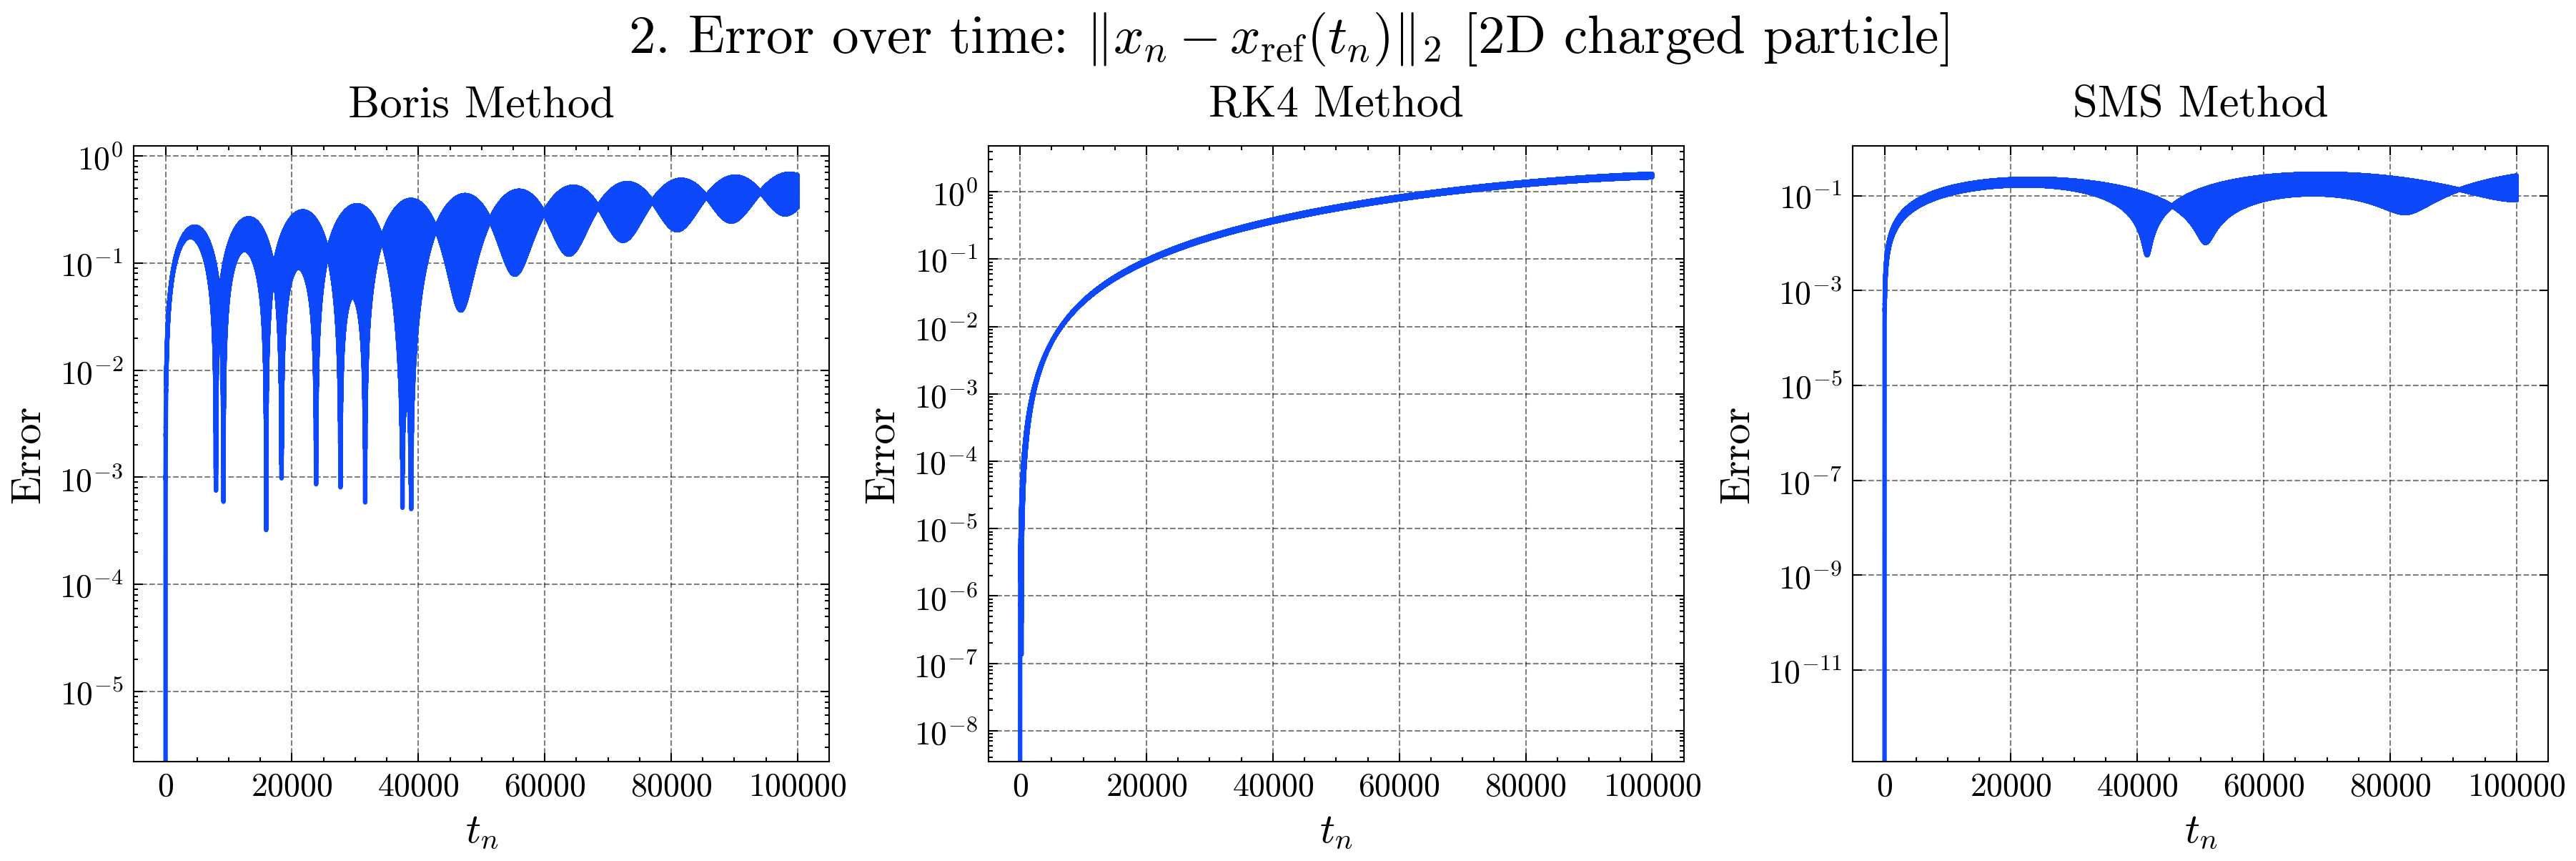

In [46]:
error_computed_boris_2D = error(x_reference_2D[:-1, :], x_boris_2D)
error_computed_RK4_2D = error(x_reference_2D, x_RK4_2D)
error_computed_MS_2D = error(x_reference_2D, x_MS_2D)

fig, axs = plt.subplots(1, 3, figsize=(12, 4))
fig.suptitle(
    r"2. Error over time: $\|x_n - x_{\mathrm{ref}}(t_n)\|_2$ [2D charged particle]"
)

# Boris method
axs[0].semilogy(
    t_boris_2D,
    error_computed_boris_2D,
)
axs[0].set_title("Boris Method")
axs[0].set_xlabel(r"$t_n$")
axs[0].set_ylabel(r"Error")
axs[0].set_aspect("auto")

# RK4
axs[1].semilogy(
    t,
    error_computed_RK4_2D,
)
axs[1].set_title("RK4 Method")
axs[1].set_xlabel(r"$t_n$")
axs[1].set_ylabel(r"Error")
axs[1].set_aspect("auto")

# Fourth-order symmetric multistep method
axs[2].semilogy(
    t,
    error_computed_MS_2D,
)
axs[2].set_title("SMS Method")
axs[2].set_xlabel(r"$t_n$")
axs[2].set_ylabel(r"Error")
axs[2].set_aspect("auto")

plt.show()

#### 2. Error over time
The error shown in the plots is $\|x_n - x_{\text{ref}}(t_n)\|_2$, where $x_{\text{ref}}$ is a reference solution computed with a highly accurate RK45 solver (`solve_ivp` with `rtol=1e-10`, `atol=1e-12`).  
The reference solution is therefore a numerically accurate approximation rather than an analytical one.

For the Boris method, the error oscillates and increases gradually throughout the simulation. It remains below $10^0$ and follows a slow, almost linear upward trend with small oscillations. These oscillations decrease in amplitude toward the end of the simulation, suggesting that the method becomes more stable over time. The overall behaviour indicates a steady but limited growth rather than complete stagnation.

For RK4, the error increases more steeply at the beginning but then appears to flatten out somewhat toward the end of the simulation. Its final value is slightly above that of Boris, though the difference in growth rate becomes smaller at later times. This suggests that while RK4 accumulates error faster initially, both methods end up showing comparable trends during the final part of the simulation.

For the Symmetric Multistep (SMS) method, the error shows the same initial rise seen in the other methods but then stabilizes around $10^{-1}$ with only minor oscillations. After the early transient phase, the error remains nearly constant, which indicates good long-term stability. This behaviour aligns with the expected properties of symmetric integrators that tend to maintain bounded global error over long simulations.

In summary, all methods exhibit an early jump in error followed by different long-term patterns. RK4 grows more rapidly at first and then levels off, Boris increases more slowly with diminishing oscillations, and the Symmetric Multistep method stabilizes at a nearly constant error level after the initial rise.


/var/folders/7m/vv_ld9cd50x2ywvm340_n1m40000gn/T/ipykernel_21842/3862669632.py:59: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


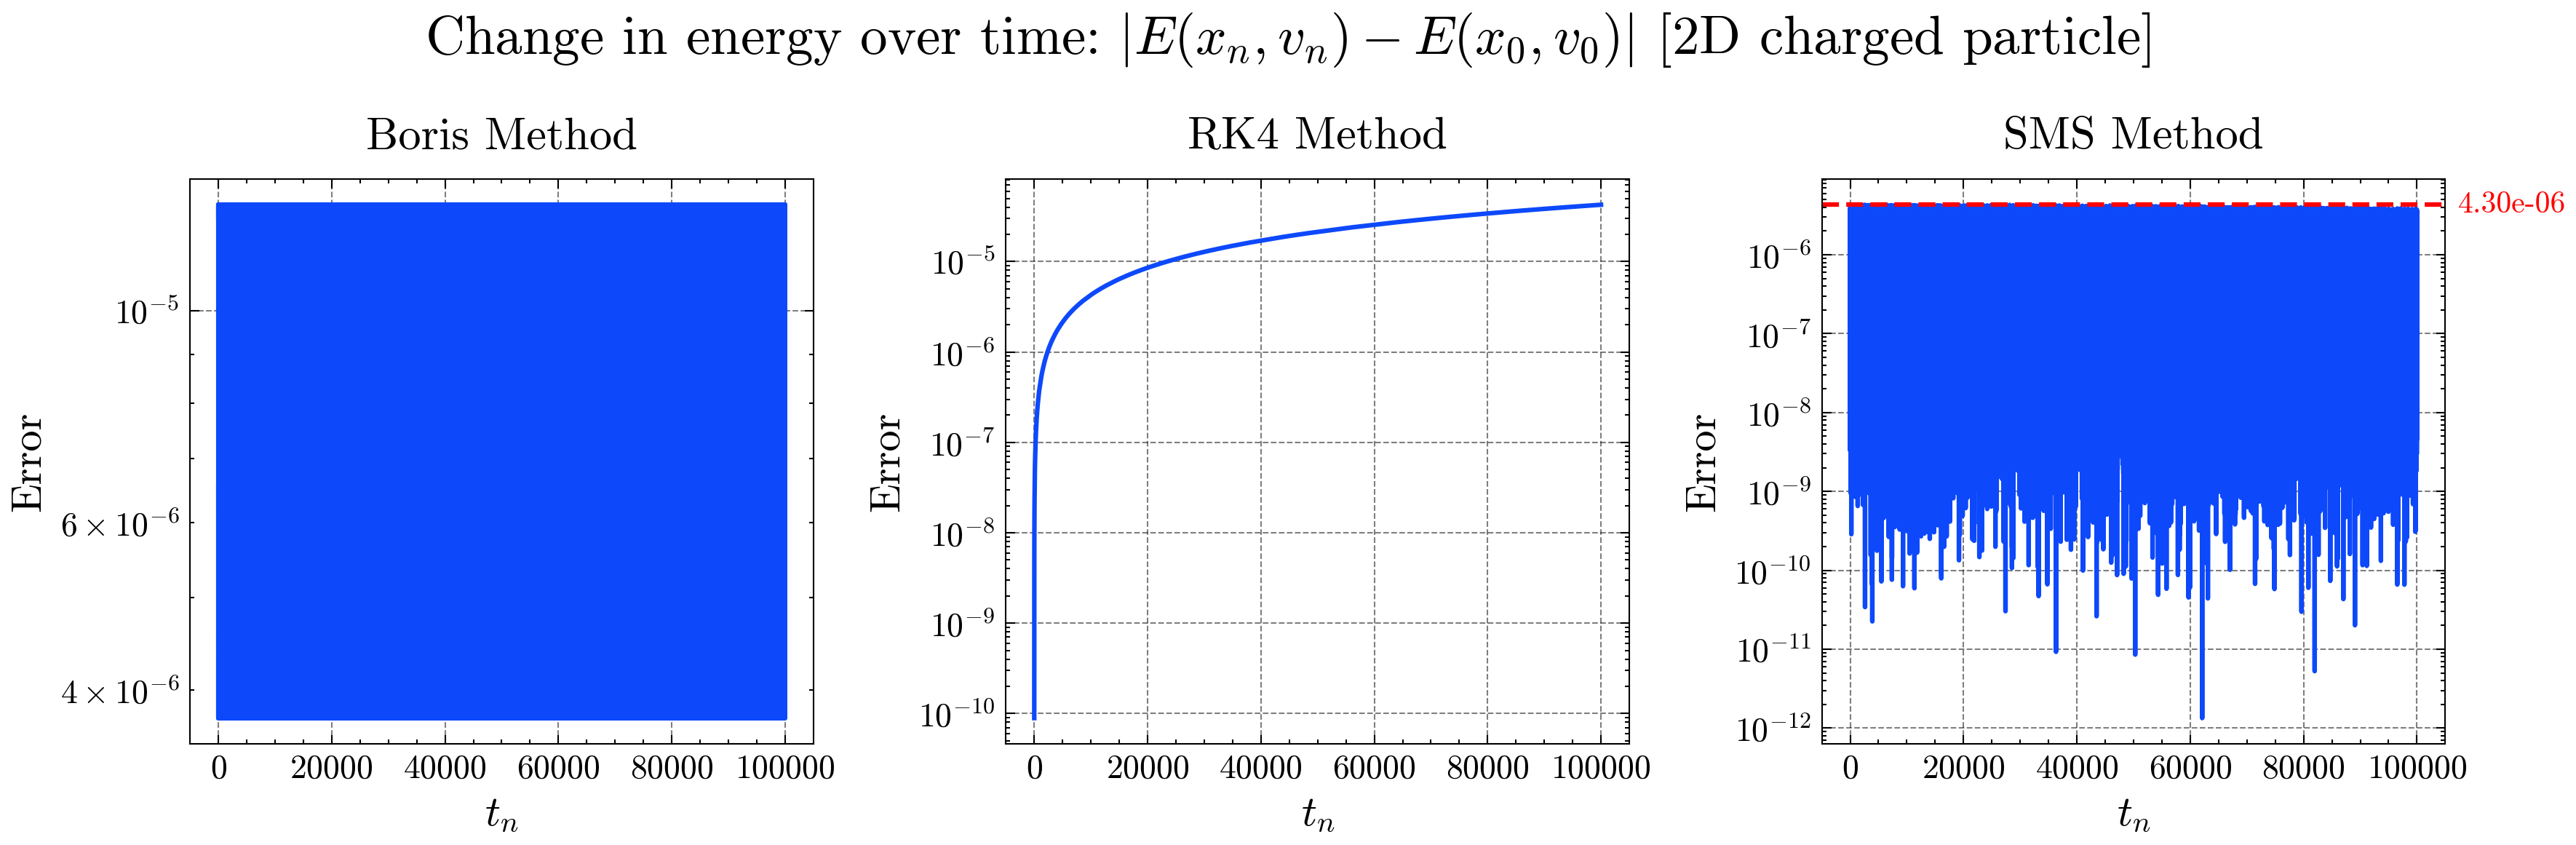

In [47]:
energy_error_boris_2D = energy_error(
    initial_energy_2D, x_boris_2D, v_boris_2D, U_2D_matrix
)
energy_error_RK4_2D = energy_error(initial_energy_2D, x_RK4_2D, v_RK4_2D, U_2D_matrix)
energy_error_MS_2D = energy_error(initial_energy_2D, x_MS_2D, v_MS_2D, U_2D_matrix)

idx = slice(
    2, -2
)  # we dont include first 2 and last 2 indexes because for multistep last velocities arent computed so the final energy there blows up

fig, axs = plt.subplots(1, 3, figsize=(12, 4))
fig.suptitle(
    r"Change in energy over time: $|E(x_n, v_n) - E(x_0, v_0)|$ [2D charged particle]"
)

# Boris method
axs[0].semilogy(
    t_boris_2D[idx],
    energy_error_boris_2D[idx],
)
axs[0].set_title("Boris Method")
axs[0].set_xlabel(r"$t_n$")
axs[0].set_ylabel(r"Error")
axs[0].set_aspect("auto")

# RK4
axs[1].semilogy(
    t[idx],
    energy_error_RK4_2D[idx],
)
axs[1].set_title("RK4 Method")
axs[1].set_xlabel(r"$t_n$")
axs[1].set_ylabel(r"Error")
axs[1].set_aspect("auto")

# Fourth-order symmetric multistep method
axs[2].semilogy(
    t[idx],
    energy_error_MS_2D[idx],
)
axs[2].set_title("SMS Method")
axs[2].set_xlabel(r"$t_n$")
axs[2].set_ylabel(r"Error")
axs[2].set_aspect("auto")


max_error_observed_MS = np.max(energy_error_MS_2D[idx])
axs[2].axhline(y=max_error_observed_MS, color="r", linestyle="--")
axs[2].annotate(
    f"{max_error_observed_MS:.2e}",
    xy=(1.02, max_error_observed_MS),
    xycoords=("axes fraction", "data"),
    color="red",
    va="center",
    ha="left",
)


plt.tight_layout()
plt.show()

#### 3. Energy conservation
The energy error is defined as  

$$
e_n = |E(x_n, v_n) - E(x_0, v_0)|
$$

where  

$$
E(x, v) = \tfrac{1}{2}\|v\|^2 + U(x).
$$

For the Boris method, the energy error stays roughly around $5\times10^{-5}$ throughout the entire simulation. The plot appears as a narrow, flat band with no visible upward trend, indicating that the method keeps the energy variation small and approximately constant over time. The slight vertical thickness in the band reflects small fluctuations rather than a systematic drift.

For RK4, the energy error increases gradually and ends slightly above $10^{-5}$ near the end of the simulation. The curve rises slowly before flattening somewhat at the end. Even though its final magnitude is of the same order as the Boris method, the continuous upward trend suggests that RK4 accumulates small energy errors over time instead of keeping them confined to a fixed range.

For the Symmetric Multistep (SMS) method, the energy error remains below a clear upper limit, just above $10^{-6}$. The plot shows a thin layer of values that stay under this level throughout the entire time interval. This indicates that the method keeps the energy tightly bounded with no visible drift, and that the error never exceeds this upper limit.

In summary, both the Boris and the Symmetric Multistep methods maintain stable energy behaviour over long times, with the Symmetric Multistep method showing the smallest and most consistent energy variation. RK4, while within a similar numerical range, shows a gradual upward trend that reflects a slow loss of energy conservation over time. This is consistent with the expected results: the Boris and Symmetric Multistep methods are geometric integrators designed to preserve physical invariants such as energy, while the standard RK4 method is not and therefore accumulates small errors over long simulations. The results therefore agree well with the theoretical behaviour described for these methods.

For the symmetric multistep method, the energy error is bounded below an upper limit, specifically ${4.30 \times 10^{-6}}$, up to the simulation end time of $T=10^5$. This verifies **Theorem 3.2** for an $s$-stable symmetric multistep method, which guarantees energy conservation up to $O(h^p)$ over a long time scale $T_{max} \sim O(h^{-p-2})$. Using the method's order $p=4$ and the step size $h=0.1$, the guaranteed time scale is ${T_{max} \sim O(h^{-6}) \sim O(10^6)}$, so our simulation time $T=10^5$ is within the guaranteed range. Furthermore, the observed energy error $E_{obs} \approx 4.30 \times 10^{-6}$ is consistent with the predicted magnitude ${O(h^4)}$, by calculating the implied constant: $C \approx E_{obs} / h^4 = 4.30 \times 10^{-6} / (0.1)^4 \approx {0.043}$. Since the error is bounded by this constant $C$ which is independent of time, and the plot shows no growth over the entire interval, the results confirm the near-conservation property stated in **Theorem 3.2**.





### $\text{Tokamak magnetic field}$

In [22]:
reference_solution_Tokamak = reference_solution(
    ic_Tokamak, A=A_Tokamak, B=B_Tokamak, gradU=gradU_Tokamak, h=h, t_start=0, t_end=T
)

Reference Method: 100%|██████████| 1000000/1000000 [02:09<00:00, 7701.92it/s]


In [23]:
x_reference_Tokamak = np.transpose(reference_solution_Tokamak.y[:3, :])
v_reference_Tokamak = np.transpose(reference_solution_Tokamak.y[3:, :])

In [24]:
# Boris
x_boris_Tokamak, v_boris_Tokamak = boris_method(
    ic=ic_Tokamak,
    t_start=0,
    t_end=T,
    h=h,
    U=U_Tokamak,
    B=B_Tokamak,
    A=A_Tokamak,
    gradU=gradU_Tokamak,
)
v_boris_Tokamak = v_integer_steps(v_boris_Tokamak)
x_boris_Tokamak = x_boris_Tokamak[:-1, :]
t_boris_Tokamak = t[:-1]

Boris Method: 100%|██████████| 1000000/1000000 [00:04<00:00, 238889.21it/s]


In [25]:
# Classical Runge-Kutta 4
x_RK4_Tokamak, v_RK4_Tokamak = RK4_solver(
    h=h,
    B=B_Tokamak,
    gradU=gradU_Tokamak,
    ic=ic_Tokamak,
    t_start=0,
    t_end=T,
)

RK4 Method: 100%|██████████| 1000000/1000000 [00:28<00:00, 35406.88it/s]


In [26]:
# MS Method
x_MS_Tokamak, v_MS_Tokamak = multistep_iterate(
    h=h,
    B=B_Tokamak,
    A=A_Tokamak,
    A_jac=Jacobian_A_Tokamak,
    gradU=gradU_Tokamak,
    ic=ic_Tokamak,
    t_start=0,
    t_end=T,
)

Multistep Method: 100%|██████████| 999993/999993 [00:31<00:00, 31721.38it/s]


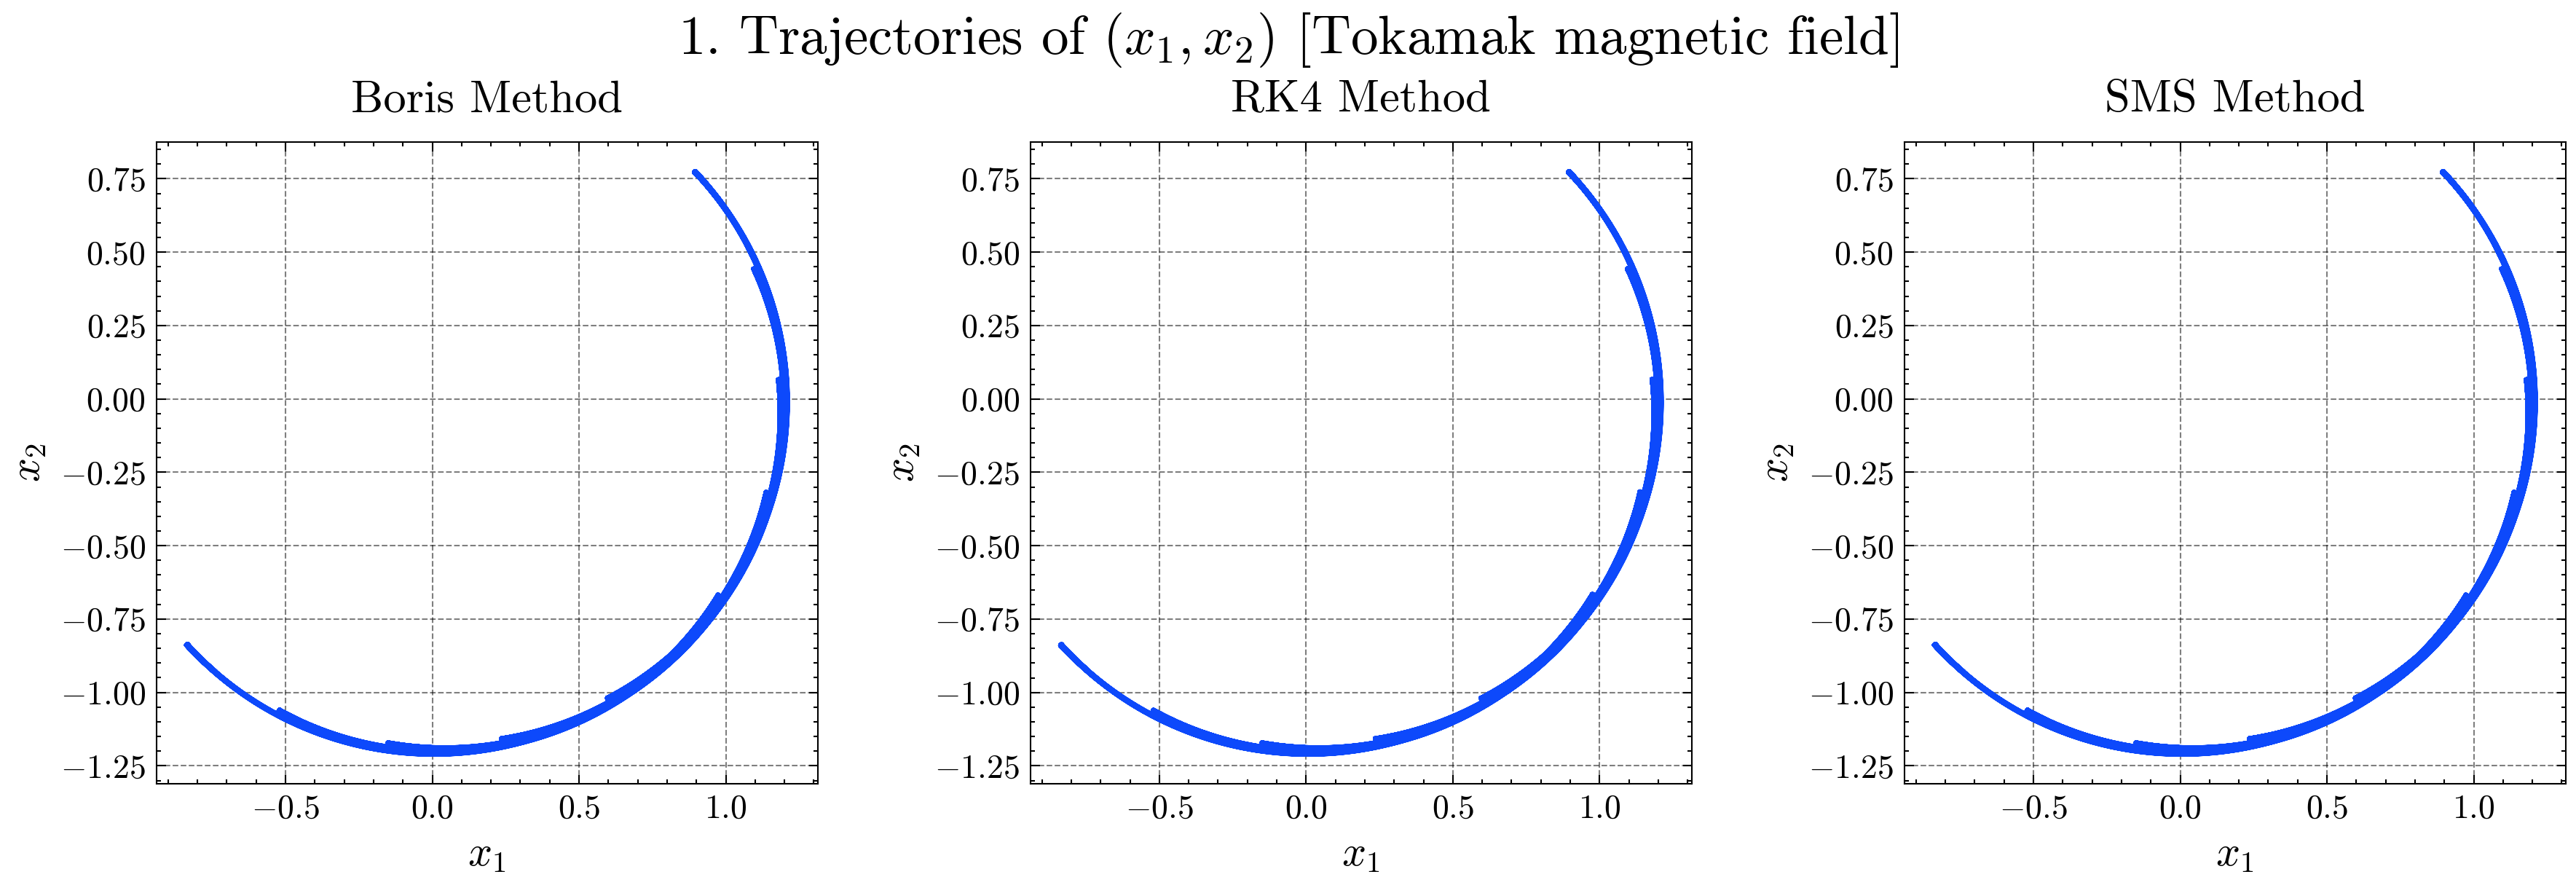

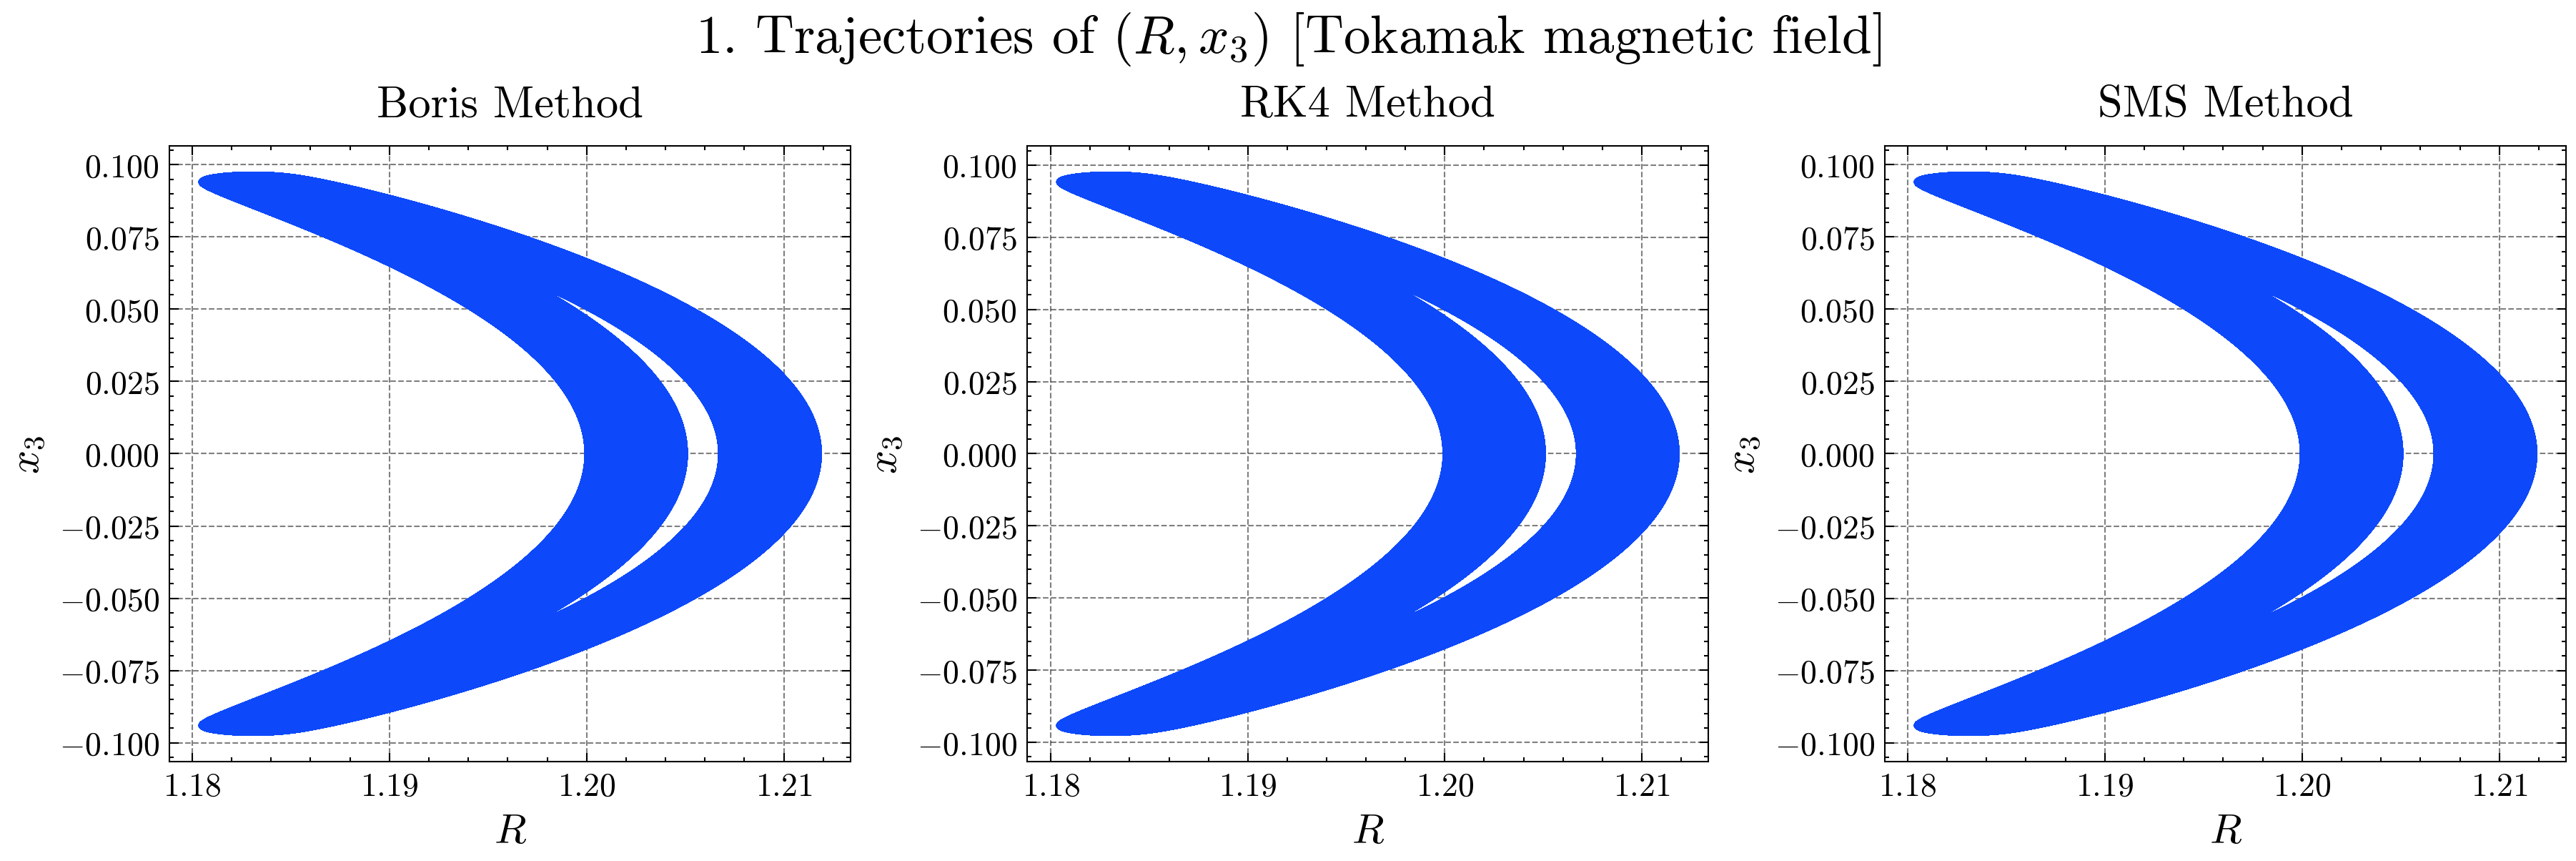

In [48]:
x1_boris_Tokamak = x_boris_Tokamak[:, 0]
x2_boris_Tokamak = x_boris_Tokamak[:, 1]
x3_boris_Tokamak = x_boris_Tokamak[:, 2]
R_boris = np.sqrt(x1_boris_Tokamak**2 + x2_boris_Tokamak**2)

x1_RK4_Tokamak = x_RK4_Tokamak[:, 0]
x2_RK4_Tokamak = x_RK4_Tokamak[:, 1]
x3_RK4_Tokamak = x_RK4_Tokamak[:, 2]
R_RK4 = np.sqrt(x1_RK4_Tokamak**2 + x2_RK4_Tokamak**2)

x1_MS_Tokamak = x_MS_Tokamak[:, 0]
x2_MS_Tokamak = x_MS_Tokamak[:, 1]
x3_MS_Tokamak = x_MS_Tokamak[:, 2]
R_MS = np.sqrt(x1_MS_Tokamak**2 + x2_MS_Tokamak**2)

# Figure 1: (x1, x2) trajectories
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
fig.suptitle(r"1. Trajectories of $(x_1, x_2)$ [Tokamak magnetic field]")

# Boris method
axs[0].plot(
    x1_boris_Tokamak,
    x2_boris_Tokamak,
)
axs[0].set_title("Boris Method")
axs[0].set_xlabel(r"$x_1$")
axs[0].set_ylabel(r"$x_2$")
axs[0].set_aspect("equal", adjustable="box")

# RK4
axs[1].plot(
    x1_RK4_Tokamak,
    x2_RK4_Tokamak,
)
axs[1].set_title("RK4 Method")
axs[1].set_xlabel(r"$x_1$")
axs[1].set_ylabel(r"$x_2$")
axs[1].set_aspect("equal", adjustable="box")

# Fourth-order symmetric multistep method
axs[2].plot(
    x1_MS_Tokamak,
    x2_MS_Tokamak,
)
axs[2].set_title("SMS Method")
axs[2].set_xlabel(r"$x_1$")
axs[2].set_ylabel(r"$x_2$")
axs[2].set_aspect("equal", adjustable="box")

plt.show()

# Figure 2: (R, x3) trajectories
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
fig.suptitle(r"1. Trajectories of $(R, x_3)$ [Tokamak magnetic field]")

# Boris method
axs[0].plot(
    R_boris,
    x3_boris_Tokamak,
)
axs[0].set_title("Boris Method")
axs[0].set_xlabel(r"$R$")
axs[0].set_ylabel(r"$x_3$")
axs[0].set_aspect("auto")

# RK4
axs[1].plot(
    R_RK4,
    x3_RK4_Tokamak,
)
axs[1].set_title("RK4 Method")
axs[1].set_xlabel(r"$R$")
axs[1].set_ylabel(r"$x_3$")
axs[1].set_aspect("auto")

# Fourth-order symmetric multistep method
axs[2].plot(
    R_MS,
    x3_MS_Tokamak,
)
axs[2].set_title("SMS Method")
axs[2].set_xlabel(r"$R$")
axs[2].set_ylabel(r"$x_3$")
axs[2].set_aspect("auto")

plt.show()

#### 1. Trajectories
The trajectories of $(x_1, x_2)$ form smooth curved paths that appear as half-moon shaped orbits. When plotted as $(R, x_3)$, where $R = \sqrt{x_1^2 + x_2^2}$, the motion forms the expected banana-shaped structure. This pattern reflects the so-called banana orbit that characterizes charged particle motion in a Tokamak magnetic field, where the particle is confined within a limited region of space. All three numerical methods produce nearly identical trajectories, and no visible differences can be seen between them. This indicates that the chosen step size $h = 0.1$ is sufficiently small for all methods to capture the particle motion accurately.


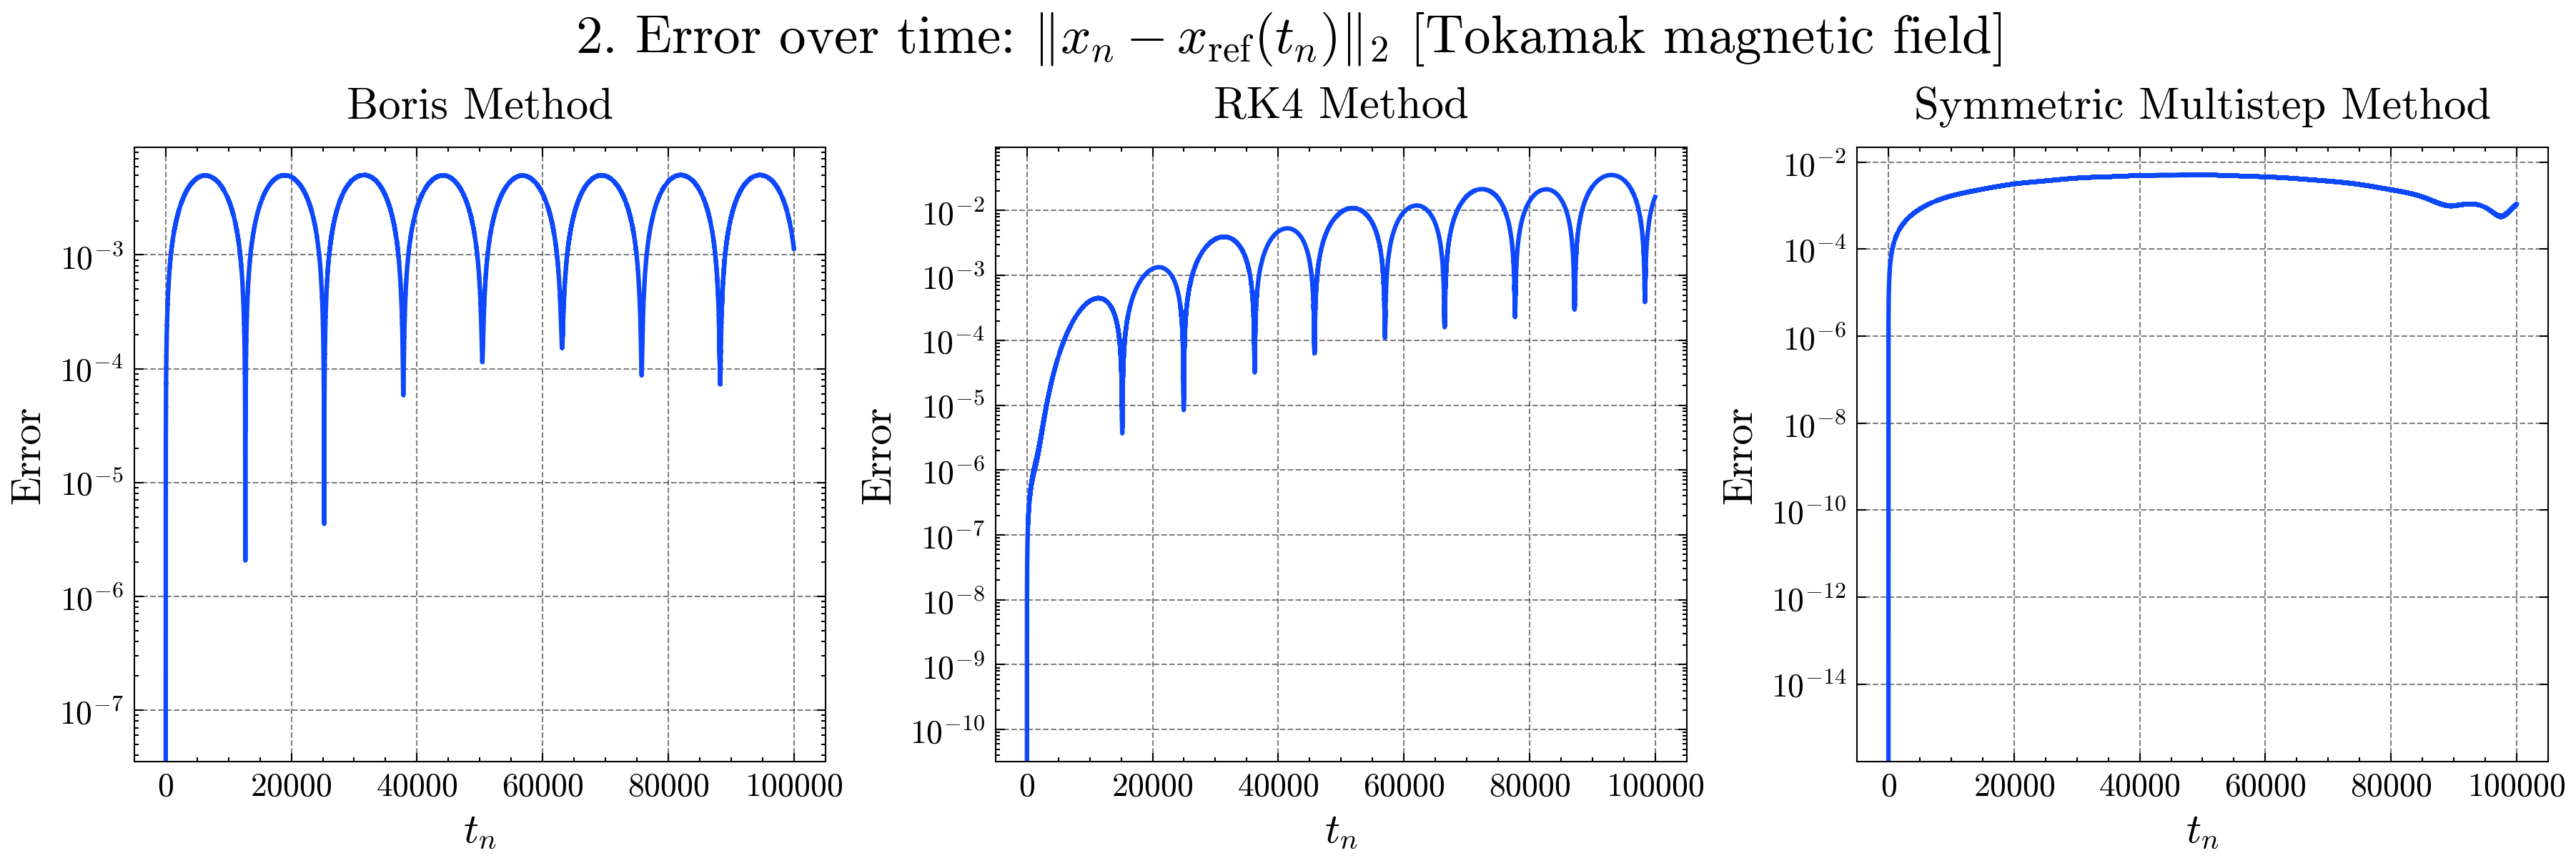

In [49]:
error_computed_boris_Tokamak = error(x_reference_Tokamak[:-1, :], x_boris_Tokamak)
error_computed_RK4_Tokamak = error(x_reference_Tokamak, x_RK4_Tokamak)
error_computed_MS_Tokamak = error(x_reference_Tokamak, x_MS_Tokamak)

fig, axs = plt.subplots(1, 3, figsize=(12, 4))
fig.suptitle(
    r"2. Error over time: $\|x_n - x_{\mathrm{ref}}(t_n)\|_2$ [Tokamak magnetic field]"
)

# Boris method
axs[0].semilogy(
    t_boris_Tokamak,
    error_computed_boris_Tokamak,
)
axs[0].set_title("Boris Method")
axs[0].set_xlabel(r"$t_n$")
axs[0].set_ylabel(r"Error")
axs[0].set_aspect("auto")

# RK4
axs[1].semilogy(
    t,
    error_computed_RK4_Tokamak,
)
axs[1].set_title("RK4 Method")
axs[1].set_xlabel(r"$t_n$")
axs[1].set_ylabel(r"Error")
axs[1].set_aspect("auto")

# Fourth-order symmetric multistep method
axs[2].semilogy(
    t,
    error_computed_MS_Tokamak,
)
axs[2].set_title("Symmetric Multistep Method")
axs[2].set_xlabel(r"$t_n$")
axs[2].set_ylabel(r"Error")
axs[2].set_aspect("auto")

plt.show()

#### 2. Error over time
The error is measured as $\|x_n - x_{\text{ref}}(t_n)\|_2$, where $x_{\text{ref}}$ is a reference solution computed with a high-accuracy RK45 solver. All three methods display an initial transient followed by distinct long-time behaviour.

For the Boris method, the error remains below a clear upper limit a little above $10^{-3}$. The curve shows a regular oscillatory pattern with no visible long-term growth over the simulated interval.

For RK4, the error exhibits a similar oscillatory pattern but with a slow upward drift over time. The curve rises gradually and finishes a little above $10^{-2}$. The trend indicates accumulation of error over long integrations.

For the Symmetric Multistep (SMS) method, the error increases rapidly from near zero to a level just below $10^{-2}$ and then stays near that level for the remainder of the run. The curve appears bounded by a line slightly below $10^{-2}$, with small variations around that level. This suggests stable long-time behaviour once the initial transient has passed.

In summary, the Boris and Symmetric Multistep methods both maintain stable and bounded errors over long times, while RK4 shows a gradual increase. This agrees with the expected results: the geometric methods (Boris and SMS) preserve the structure of the system and therefore prevent long-term error growth, whereas RK4 slowly accumulates error during long simulations.


/var/folders/7m/vv_ld9cd50x2ywvm340_n1m40000gn/T/ipykernel_21842/3644132177.py:61: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


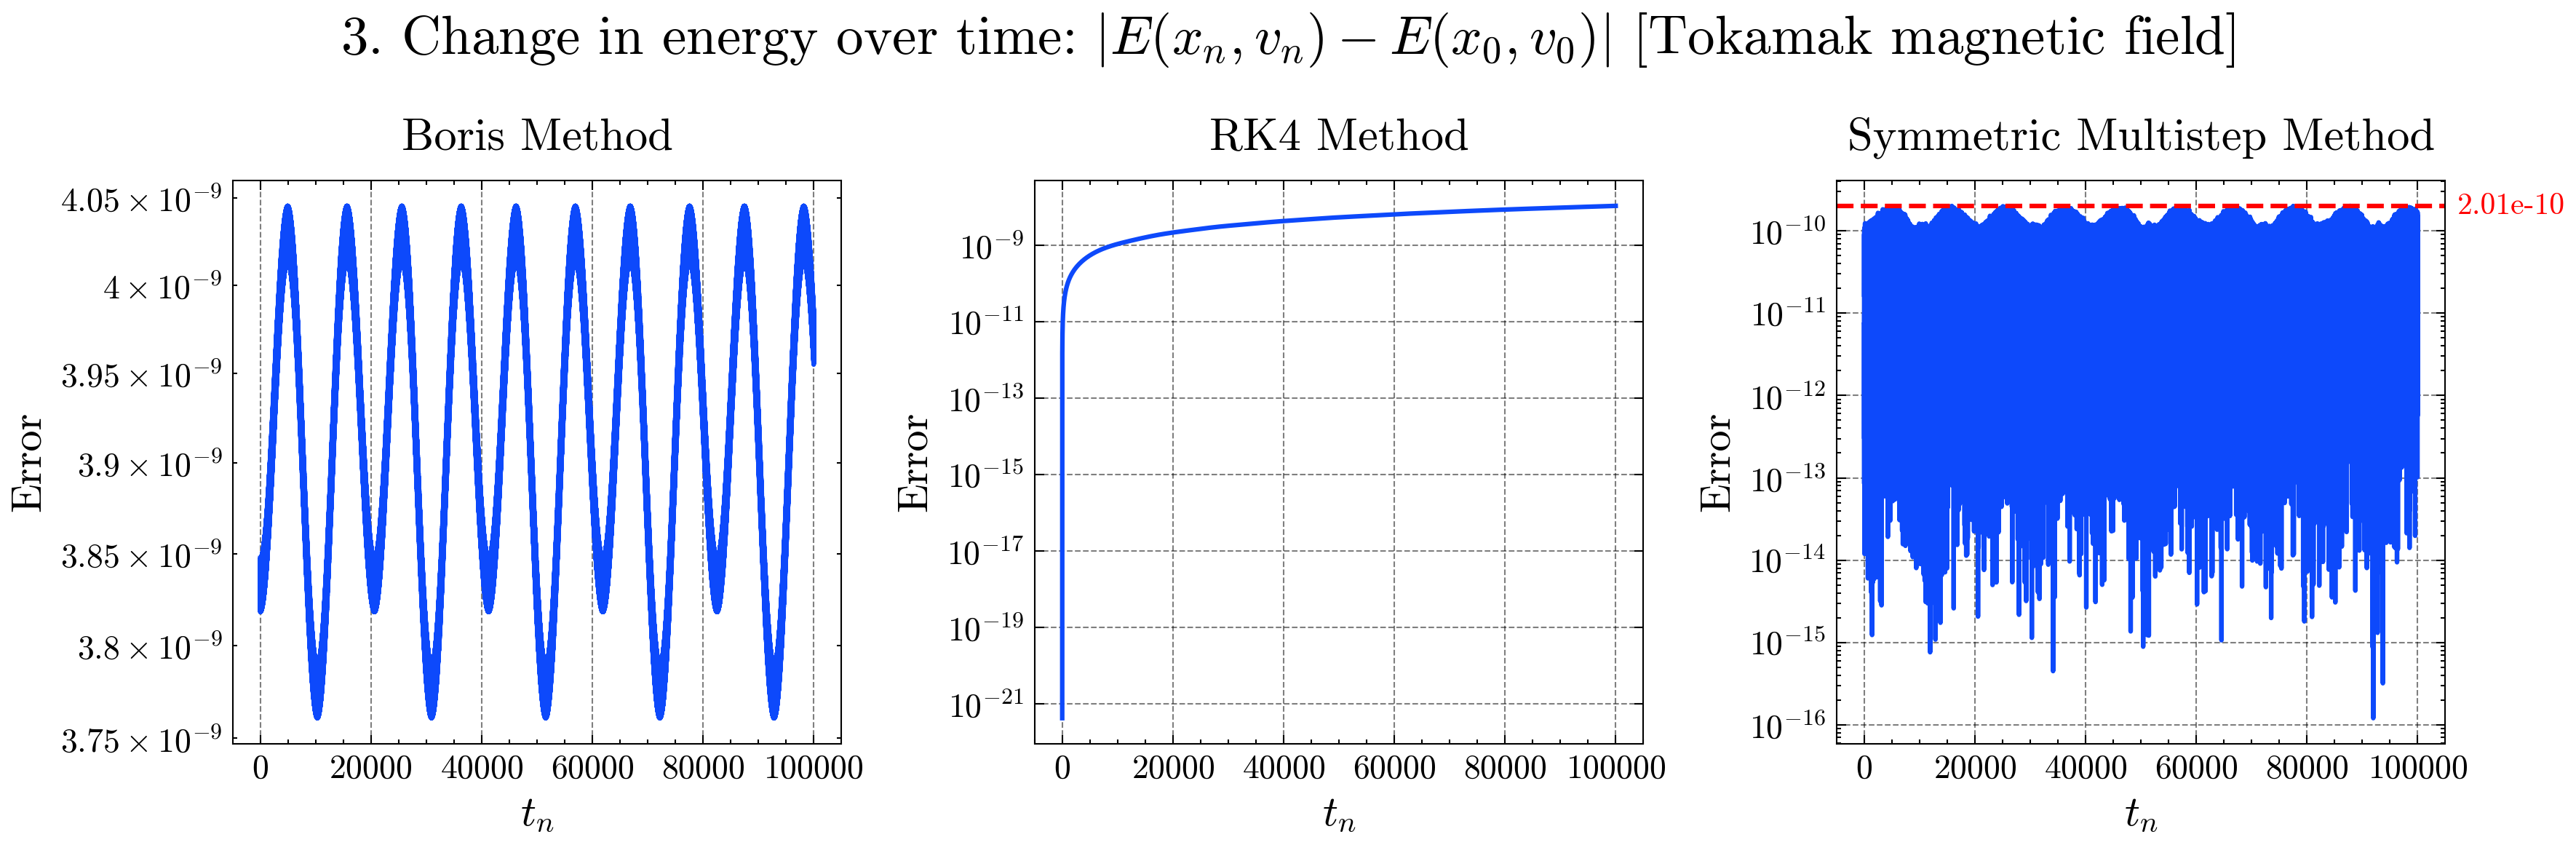

In [50]:
energy_error_boris_Tokamak = energy_error(
    initial_energy_Tokamak, x_boris_Tokamak, v_boris_Tokamak, U_Tokamak_matrix
)
energy_error_RK4_Tokamak = energy_error(
    initial_energy_Tokamak, x_RK4_Tokamak, v_RK4_Tokamak, U_Tokamak_matrix
)
energy_error_MS_Tokamak = energy_error(
    initial_energy_Tokamak, x_MS_Tokamak, v_MS_Tokamak, U_Tokamak_matrix
)

idx = slice(
    2, -2
)  # we dont include first 2 and last 2 indexes because for multistep last velocities arent computed so the final energy there blows up

fig, axs = plt.subplots(1, 3, figsize=(12, 4))
fig.suptitle(
    r"3. Change in energy over time: $|E(x_n, v_n) - E(x_0, v_0)|$ [Tokamak magnetic field]"
)

# Boris method
axs[0].semilogy(
    t_boris_Tokamak,
    energy_error_boris_Tokamak,
)
axs[0].set_title("Boris Method")
axs[0].set_xlabel(r"$t_n$")
axs[0].set_ylabel(r"Error")
axs[0].set_aspect("auto")

# RK4
axs[1].semilogy(
    t,
    energy_error_RK4_Tokamak,
)
axs[1].set_title("RK4 Method")
axs[1].set_xlabel(r"$t_n$")
axs[1].set_ylabel(r"Error")
axs[1].set_aspect("auto")

# Fourth-order symmetric multistep method
axs[2].semilogy(
    t[idx],
    energy_error_MS_Tokamak[idx],
)
axs[2].set_title("Symmetric Multistep Method")
axs[2].set_xlabel(r"$t_n$")
axs[2].set_ylabel(r"Error")
axs[2].set_aspect("auto")

max_error_observed_MS = np.max(energy_error_MS_Tokamak[idx])
axs[2].axhline(y=max_error_observed_MS, color="r", linestyle="--")
axs[2].annotate(
    f"{max_error_observed_MS:.2e}",
    xy=(1.02, max_error_observed_MS),
    xycoords=("axes fraction", "data"),
    color="red",
    va="center",
    ha="left",
)

plt.tight_layout()
plt.show()

#### 3. Energy conservation
For the Boris method, the energy error oscillates in a very regular pattern between roughly $3.75\times10^{-9}$ and $4.05\times10^{-9}$ throughout the entire simulation. The amplitude and frequency of the oscillations remain constant, showing that the method preserves energy extremely well with no visible drift over time.

For RK4, the energy error rises quickly at the start and then gradually increases, reaching around $10^{-9}$ by the end of the simulation. Although the rate of growth slows toward the end, there is still a clear upward trend. This indicates that RK4 slowly accumulates energy error over long simulations.

For the Symmetric Multistep (SMS) method, the energy error stays below an oscillating upper bound around $10^{-10}$. The upper edge of the band varies slightly in a smooth, wave-like pattern, while the area beneath it is filled with values that remain under this limit. This shows that the energy is tightly bounded but that the bound itself varies periodically, rather than remaining perfectly. This verifies **Theorem 3.2** for an $s$-stable symmetric multistep method. With the method order ${p=4}$ and the step size ${h=0.1}$, the theorem guarantees conservation up to $O(h^4)$ over a time scale $T_{max} \sim O(h^{-6}) \sim O(10^6)$, so $T=10^5$ is within the boundary. The observed maximum energy error $E_{obs} \approx 10^{-10}$ is consistent with the order ${O(h^4)}$; calculating the implied constant yields $C \approx E_{obs} / h^4 \approx 10^{-10} / (0.1)^4 = {10^{-6}}$.




In summary, both the Boris and Symmetric Multistep methods maintain excellent energy stability, with the SMS method achieving the smallest error and showing only small oscillations in its upper bound. RK4, while still accurate for shorter times, displays a gradual increase in energy error over the full simulation. This is the expected outcome: the geometric methods (Boris and SMS) preserve the system’s invariants over long times, while RK4 accumulates small energy errors due to its non-geometric nature.


## $\text{B. Order verification and work precision diagrams}$

In [30]:
step_sizes = [h / 2**i for i in range(3)]  # h, h/2, h/4
Tb = 1000

### $\text{2D charged particle}$

Multistep Method: 100%|██████████| 39993/39993 [00:01<00:00, 32281.58it/s]
/var/folders/7m/vv_ld9cd50x2ywvm340_n1m40000gn/T/ipykernel_21842/2153505772.py:107: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


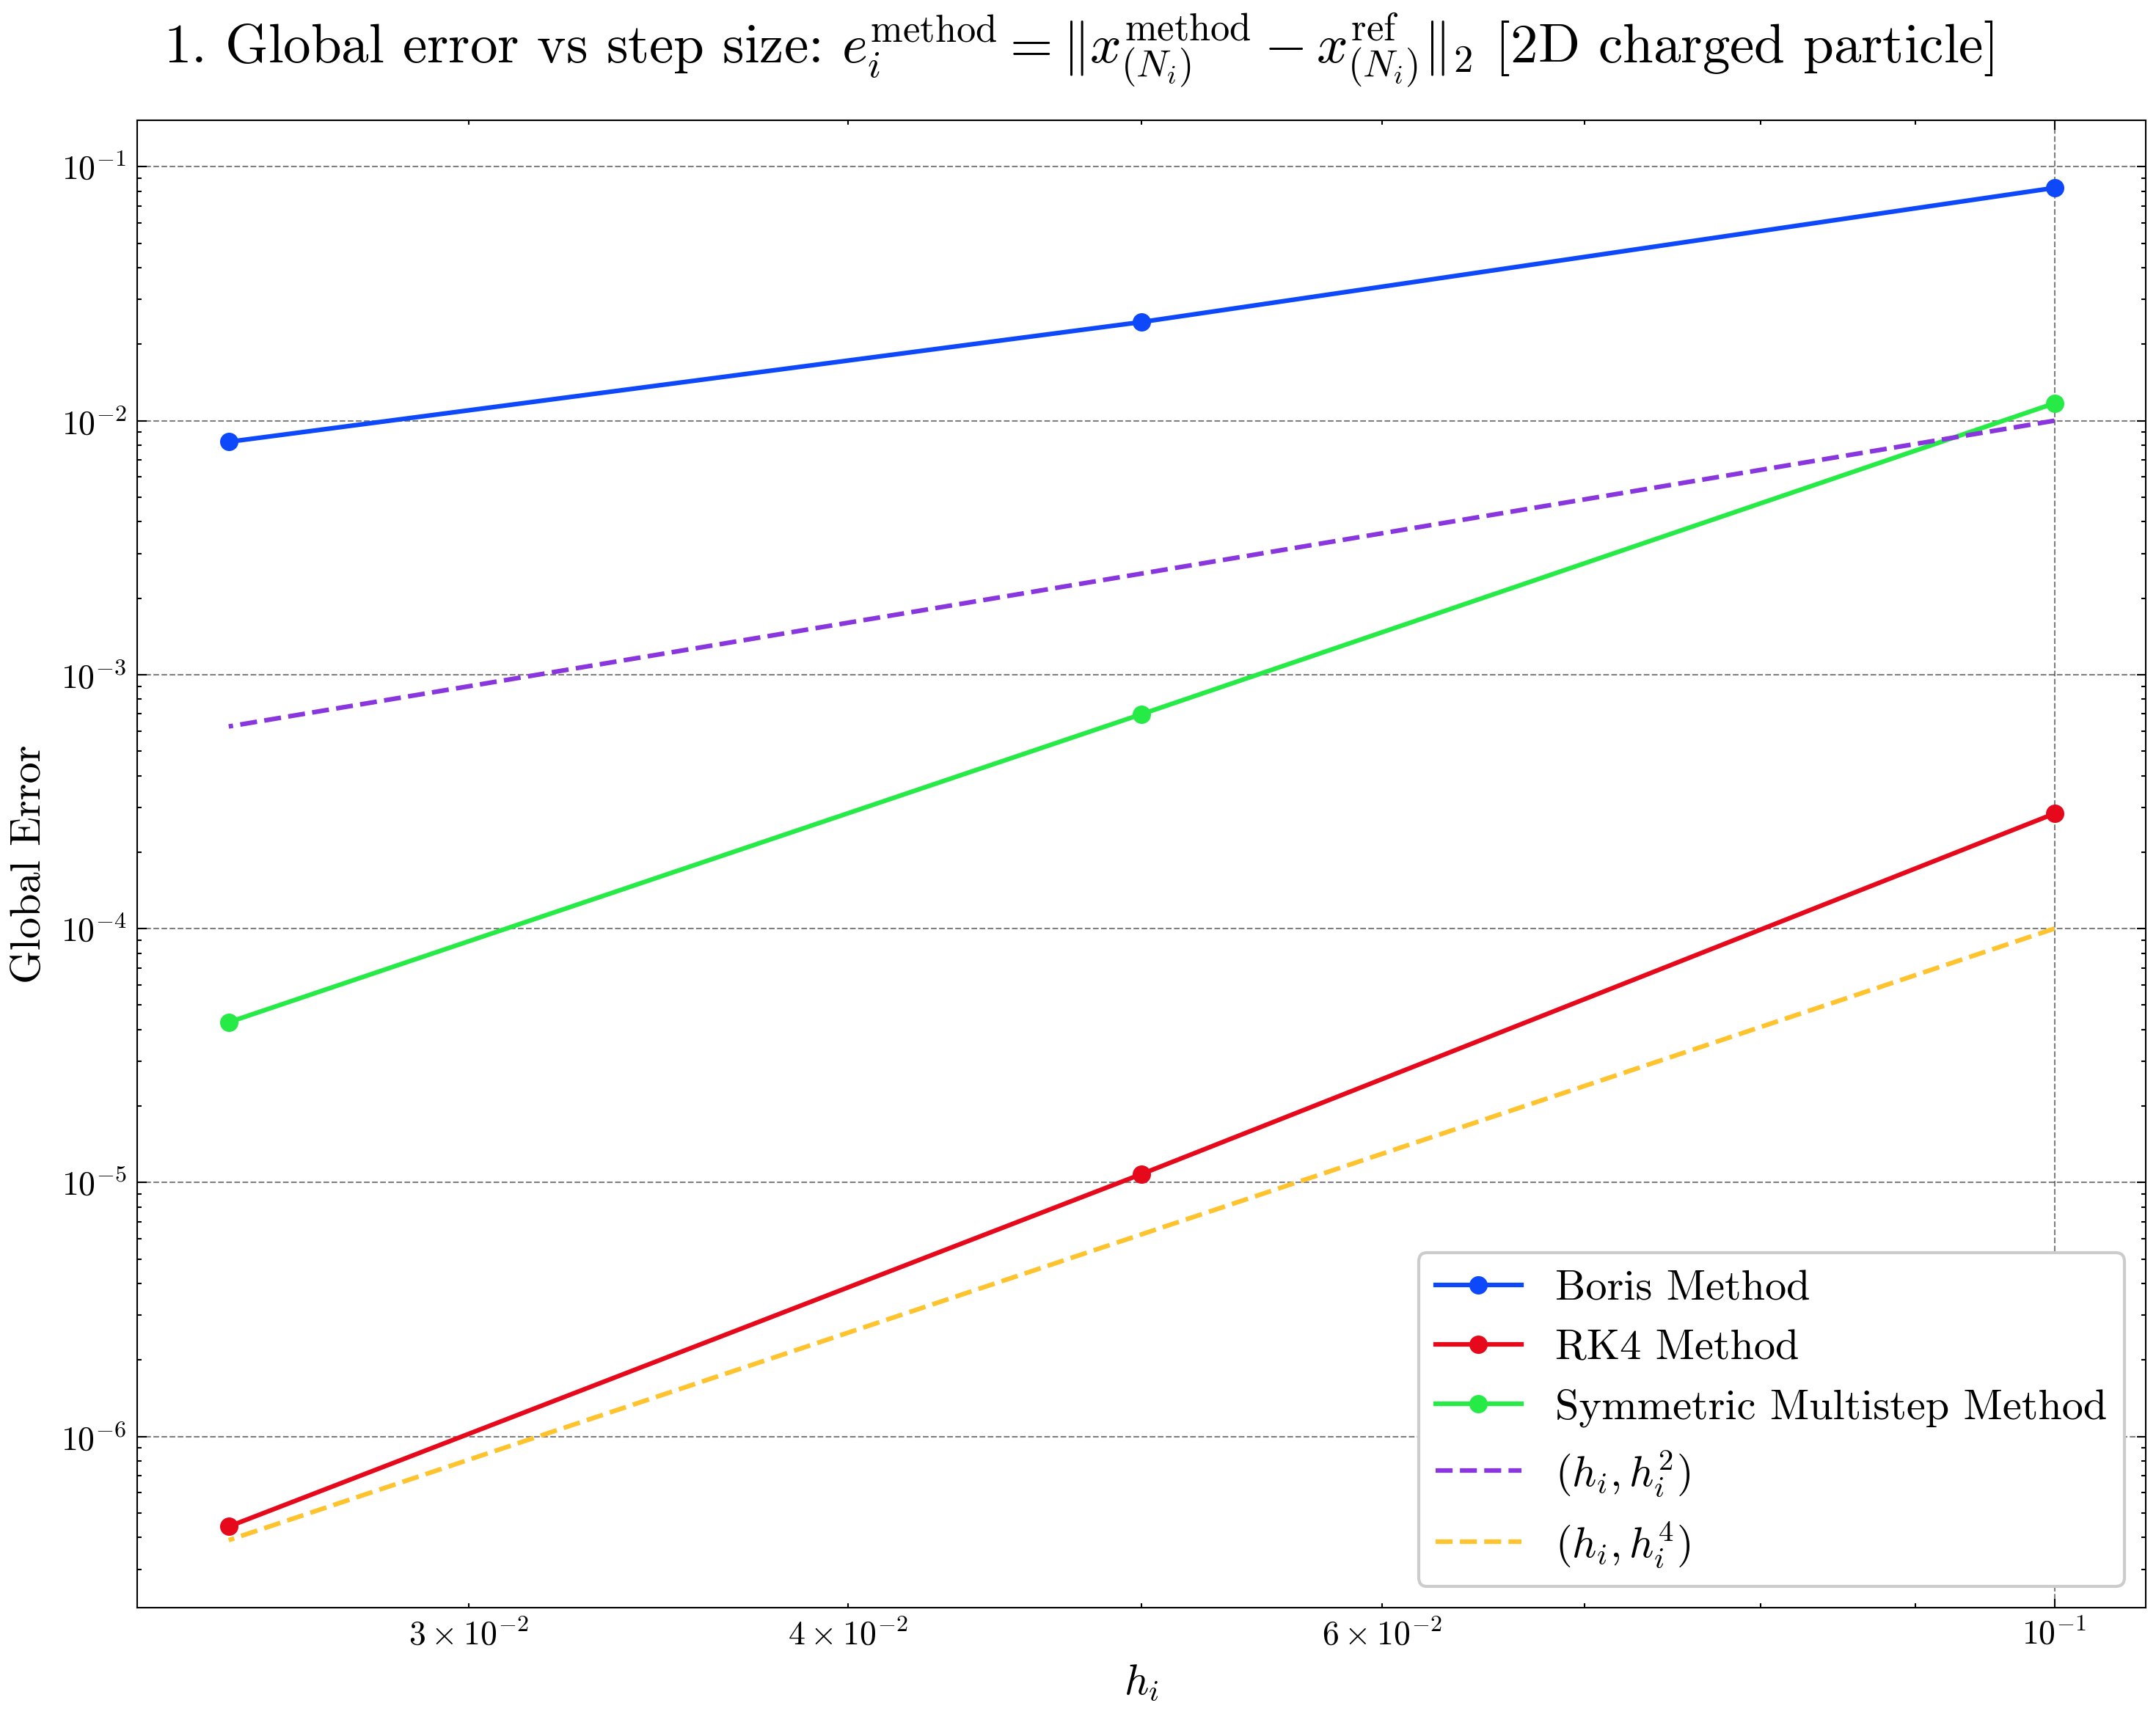

/var/folders/7m/vv_ld9cd50x2ywvm340_n1m40000gn/T/ipykernel_21842/2153505772.py:134: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


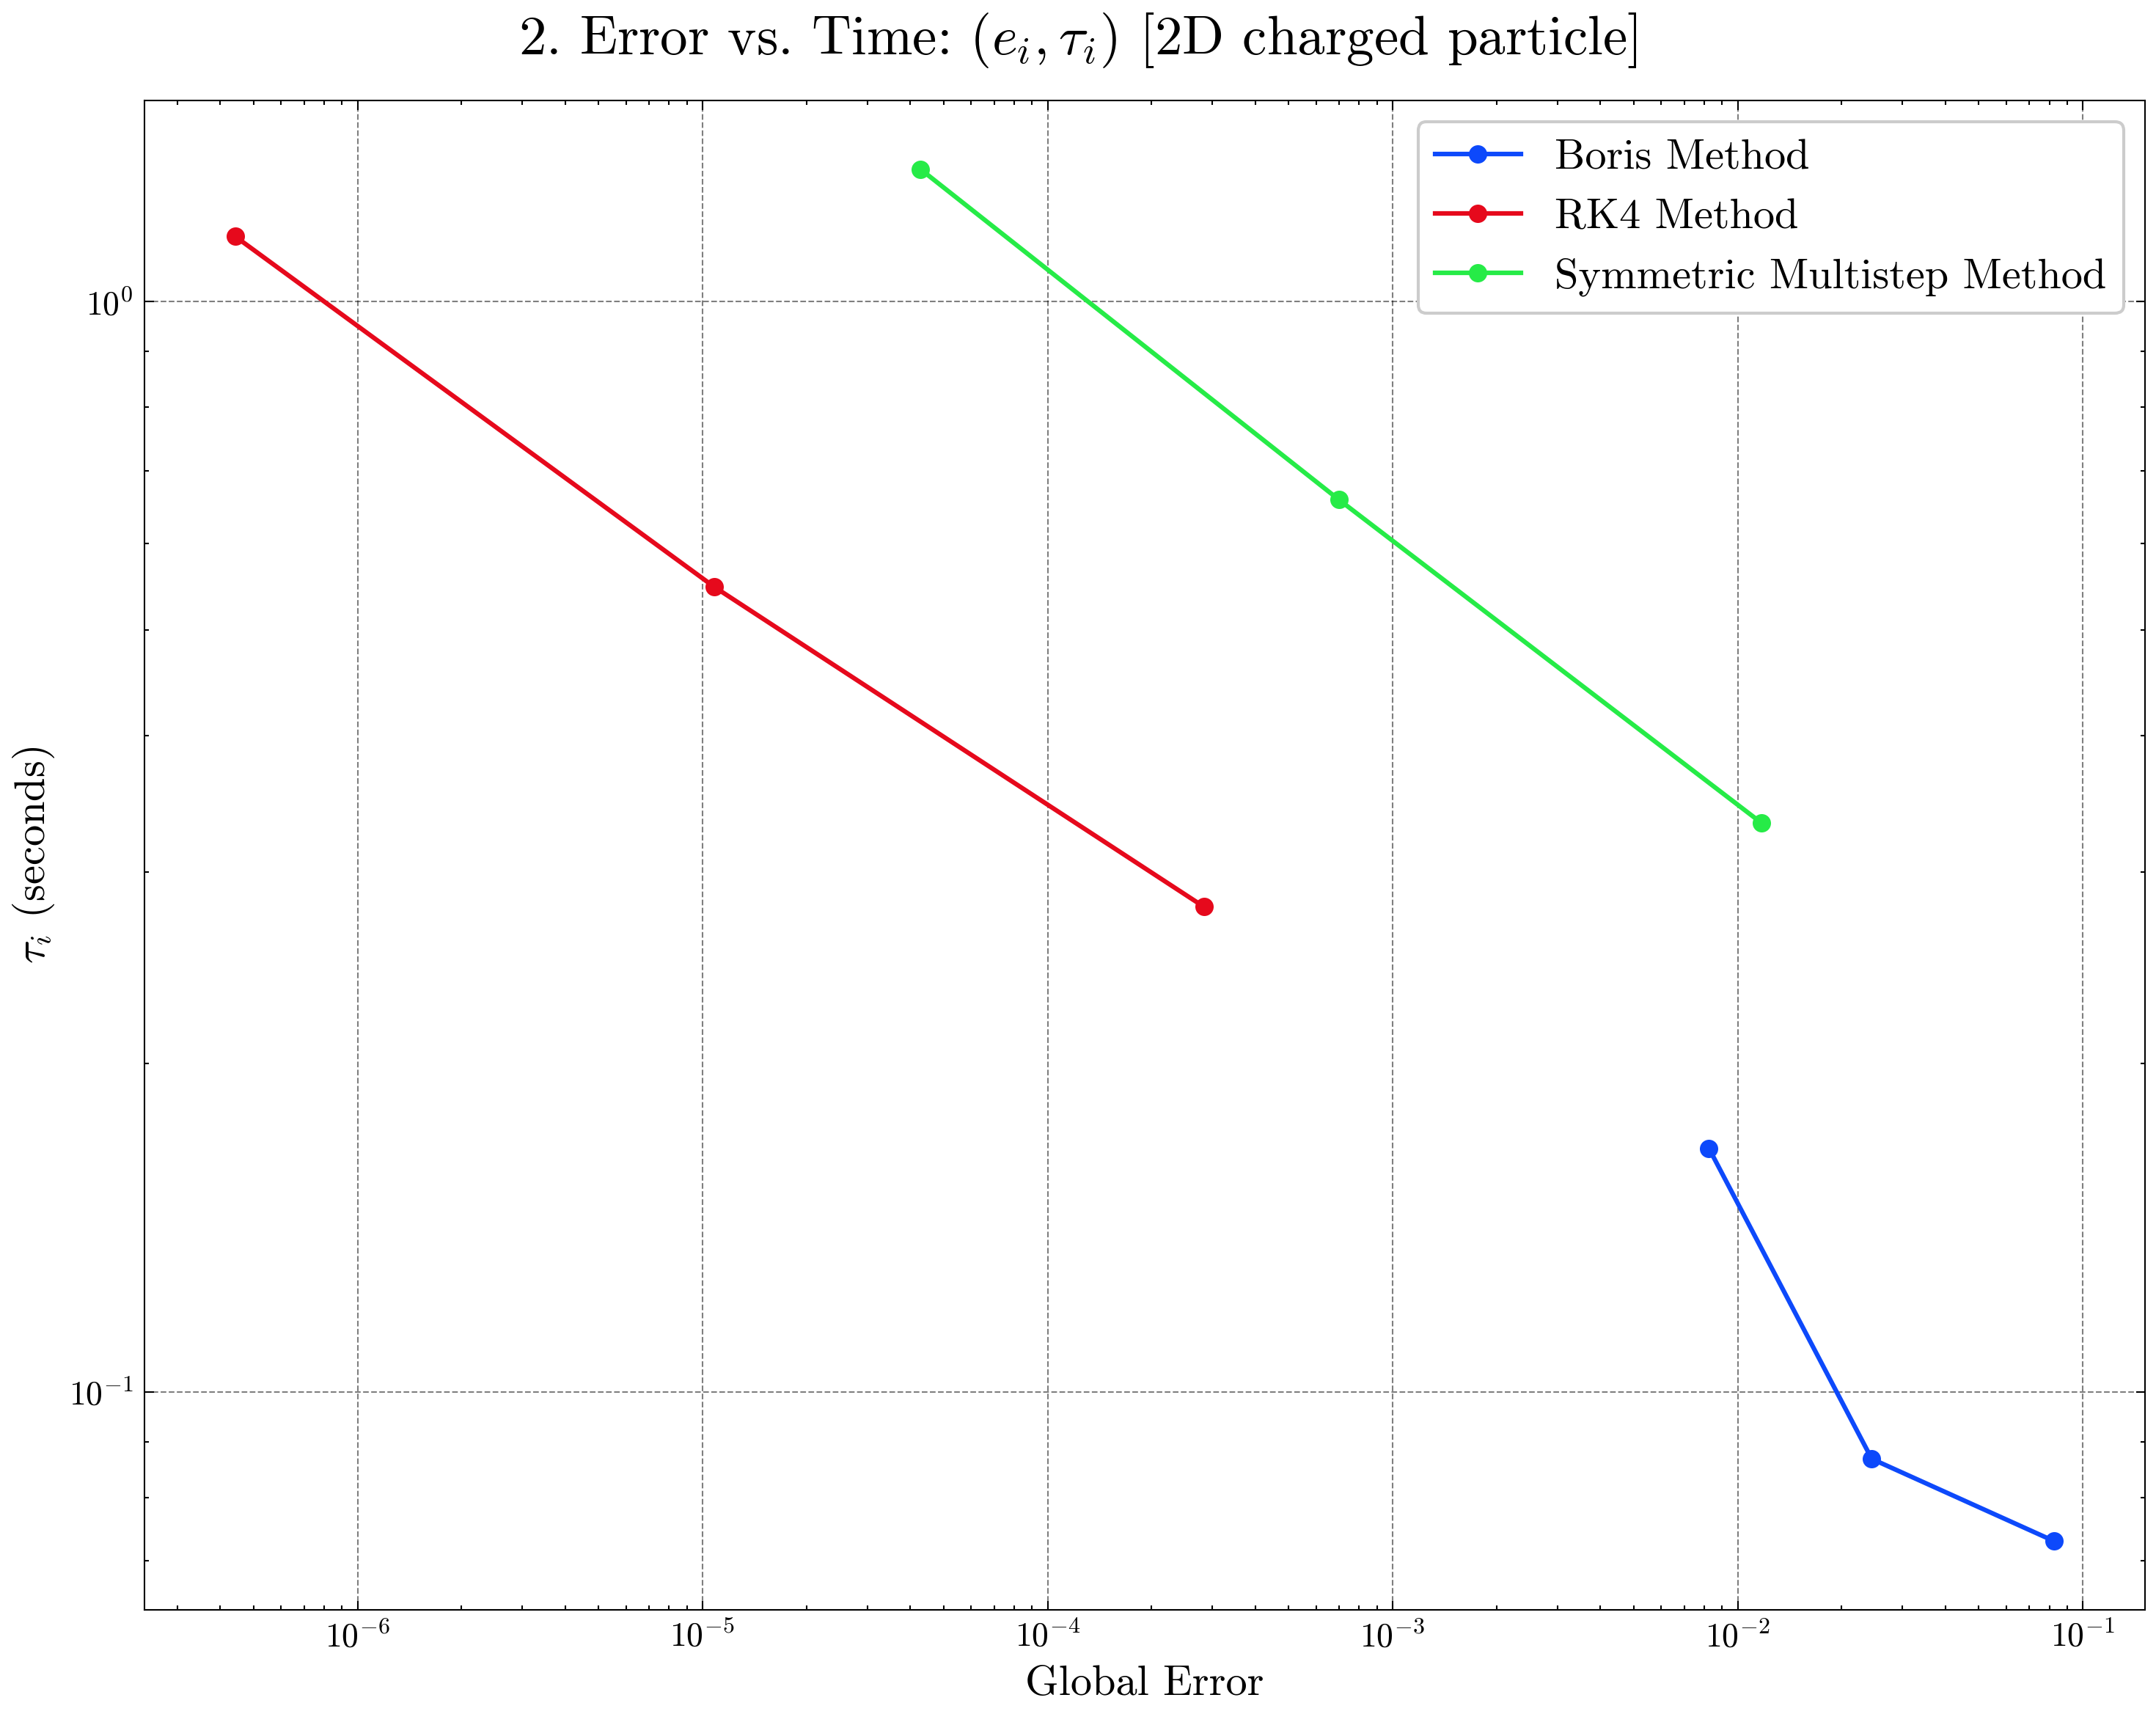

In [52]:
global_errors_boris_2D = []
times_boris_2D = []
global_errors_RK4_2D = []
times_RK4_2D = []
global_errors_MS_2D = []
times_MS_2D = []

# compute for each step size
for h_i in step_sizes:
    reference_solution_2D_b = reference_solution(
        ic_2D,
        A=A_2D,
        B=B_2D,
        gradU=gradU_2D,
        h=h_i,
        t_start=0,
        t_end=Tb,
    )
    xB_reference_2D = np.transpose(reference_solution_2D_b.y[:3, :])
    vB_reference_2D = np.transpose(reference_solution_2D_b.y[3:, :])

    # Boris
    start_time = time.perf_counter()
    xB_boris_2D, vB_boris_2D = boris_method(
        ic=ic_2D,
        t_start=0,
        t_end=Tb,
        h=h_i,
        U=U_2D,
        B=B_2D,
        A=A_2D,
        gradU=gradU_2D,
    )
    times_boris_2D.append(time.perf_counter() - start_time)
    vB_boris_2D = v_integer_steps(vB_boris_2D)
    xB_boris_2D = xB_boris_2D[:-1, :]

    # RK4
    start_time = time.perf_counter()
    xB_RK4_2D, vB_RK4_2D = RK4_solver(
        h=h_i,
        B=B_2D,
        gradU=gradU_2D,
        ic=ic_2D,
        t_start=0,
        t_end=Tb,
    )
    times_RK4_2D.append(time.perf_counter() - start_time)

    # MS
    start_time = time.perf_counter()
    xB_MS_2D, vB_MS_2D = multistep_iterate(
        h=h_i,
        B=B_2D,
        A=A_2D,
        A_jac=Jacobian_A_2D,
        gradU=gradU_2D,
        ic=ic_2D,
        t_start=0,
        t_end=Tb,
    )
    times_MS_2D.append(time.perf_counter() - start_time)

    global_errors_boris_2D.append(
        np.linalg.norm(xB_boris_2D[-1] - xB_reference_2D[-1, :], 2)
    )
    global_errors_RK4_2D.append(
        np.linalg.norm(xB_RK4_2D[-1] - xB_reference_2D[-1, :], 2)
    )
    global_errors_MS_2D.append(np.linalg.norm(xB_MS_2D[-1] - xB_reference_2D[-1, :], 2))

# Figure 1: Global error vs step size
fig1, ax1 = plt.subplots(1, 1, figsize=(10, 8))
fig1.suptitle(
    r"1. Global error vs step size: "
    r"$e_i^{\mathrm{method}} = \| x_{(N_i)}^{\mathrm{method}} - x_{(N_i)}^{\mathrm{ref}} \|_2$ "
    r"[2D charged particle]"
)
ax1.loglog(
    step_sizes,
    global_errors_boris_2D,
    "o-",
    label="Boris Method",
)
ax1.loglog(step_sizes, global_errors_RK4_2D, "o-", label="RK4 Method")
ax1.loglog(
    step_sizes,
    global_errors_MS_2D,
    "o-",
    label="Symmetric Multistep Method",
)
ax1.loglog(
    step_sizes,
    np.array(step_sizes) ** 2,
    "--",
    label=r"$(h_i, h_i^2)$",
)
ax1.loglog(
    step_sizes,
    np.array(step_sizes) ** 4,
    "--",
    label=r"$(h_i, h_i^4)$",
)
ax1.set_xlabel(r"$h_i$")
ax1.set_ylabel("Global Error")
ax1.legend()
plt.tight_layout()
plt.show()

# Figure 2: Work-precision (error vs computation time)
fig2, ax2 = plt.subplots(1, 1, figsize=(10, 8))
fig2.suptitle(r"2. Error vs. Time: $(e_i, \tau_i)$ [2D charged particle]")
ax2.loglog(
    global_errors_boris_2D,
    times_boris_2D,
    "o-",
    label="Boris Method",
)
ax2.loglog(
    global_errors_RK4_2D,
    times_RK4_2D,
    "o-",
    label="RK4 Method",
)
ax2.loglog(
    global_errors_MS_2D,
    times_MS_2D,
    "o-",
    label="Symmetric Multistep Method",
)
ax2.set_xlabel("Global Error")
ax2.set_ylabel(r"$\tau_i$ (seconds)")
ax2.legend()
plt.tight_layout()
plt.show()

#### Discussion – Order verification and work–precision diagrams




##### 1. Global error vs. step size
The log–log plot of global error versus step size shows clear straight-line behaviour for all three methods. The Boris method follows a slope parallel to the $h_i^2$ reference line, confirming that it is second-order accurate. Both the RK4 and the Symmetric Multistep (SMS) methods follow the $h_i^4$ reference line, consistent with their theoretical fourth-order accuracy. This verifies that each method converges with the expected order.



##### 2. Error vs. computation time
The work–precision diagram compares error against computation time. The Boris method is the fastest but produces the largest errors, reflecting its lower order of accuracy. The RK4 method achieves the smallest errors but requires the most computation time. The Symmetric Multistep method lies between the two: it reaches accuracy close to RK4 but with less computational cost.



##### 3. Which method is most efficient for a given tolerance?
Read the work–precision plot by drawing a horizontal line at the target error and picking the method that intersects that line with the shortest runtime. In our results, for coarser tolerances ($e \gtrsim 10^{-2}$), the Boris method is the most efficient. For tighter tolerances like ($e \lesssim 10^{-5}$), RK4 becomes the most efficient since it reaches smaller errors in less time than the other methods. The Symmetric Multistep method lies between them but is not the most efficient at the overlapping error levels in this setup.


##### 4. Conclusion
The results confirm the expected theoretical behaviour. The Boris method is efficient for moderate accuracy requirements, RK4 provides the highest accuracy but at a higher cost, and the Symmetric Multistep method offers the best balance between accuracy and efficiency. These findings are in line with what is theoretically predicted for geometric integrators and standard one-step methods.

### $\text{Tokamak magnetic field}$

Multistep Method: 100%|██████████| 39993/39993 [00:01<00:00, 33165.95it/s]
/var/folders/7m/vv_ld9cd50x2ywvm340_n1m40000gn/T/ipykernel_21842/3202822.py:114: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


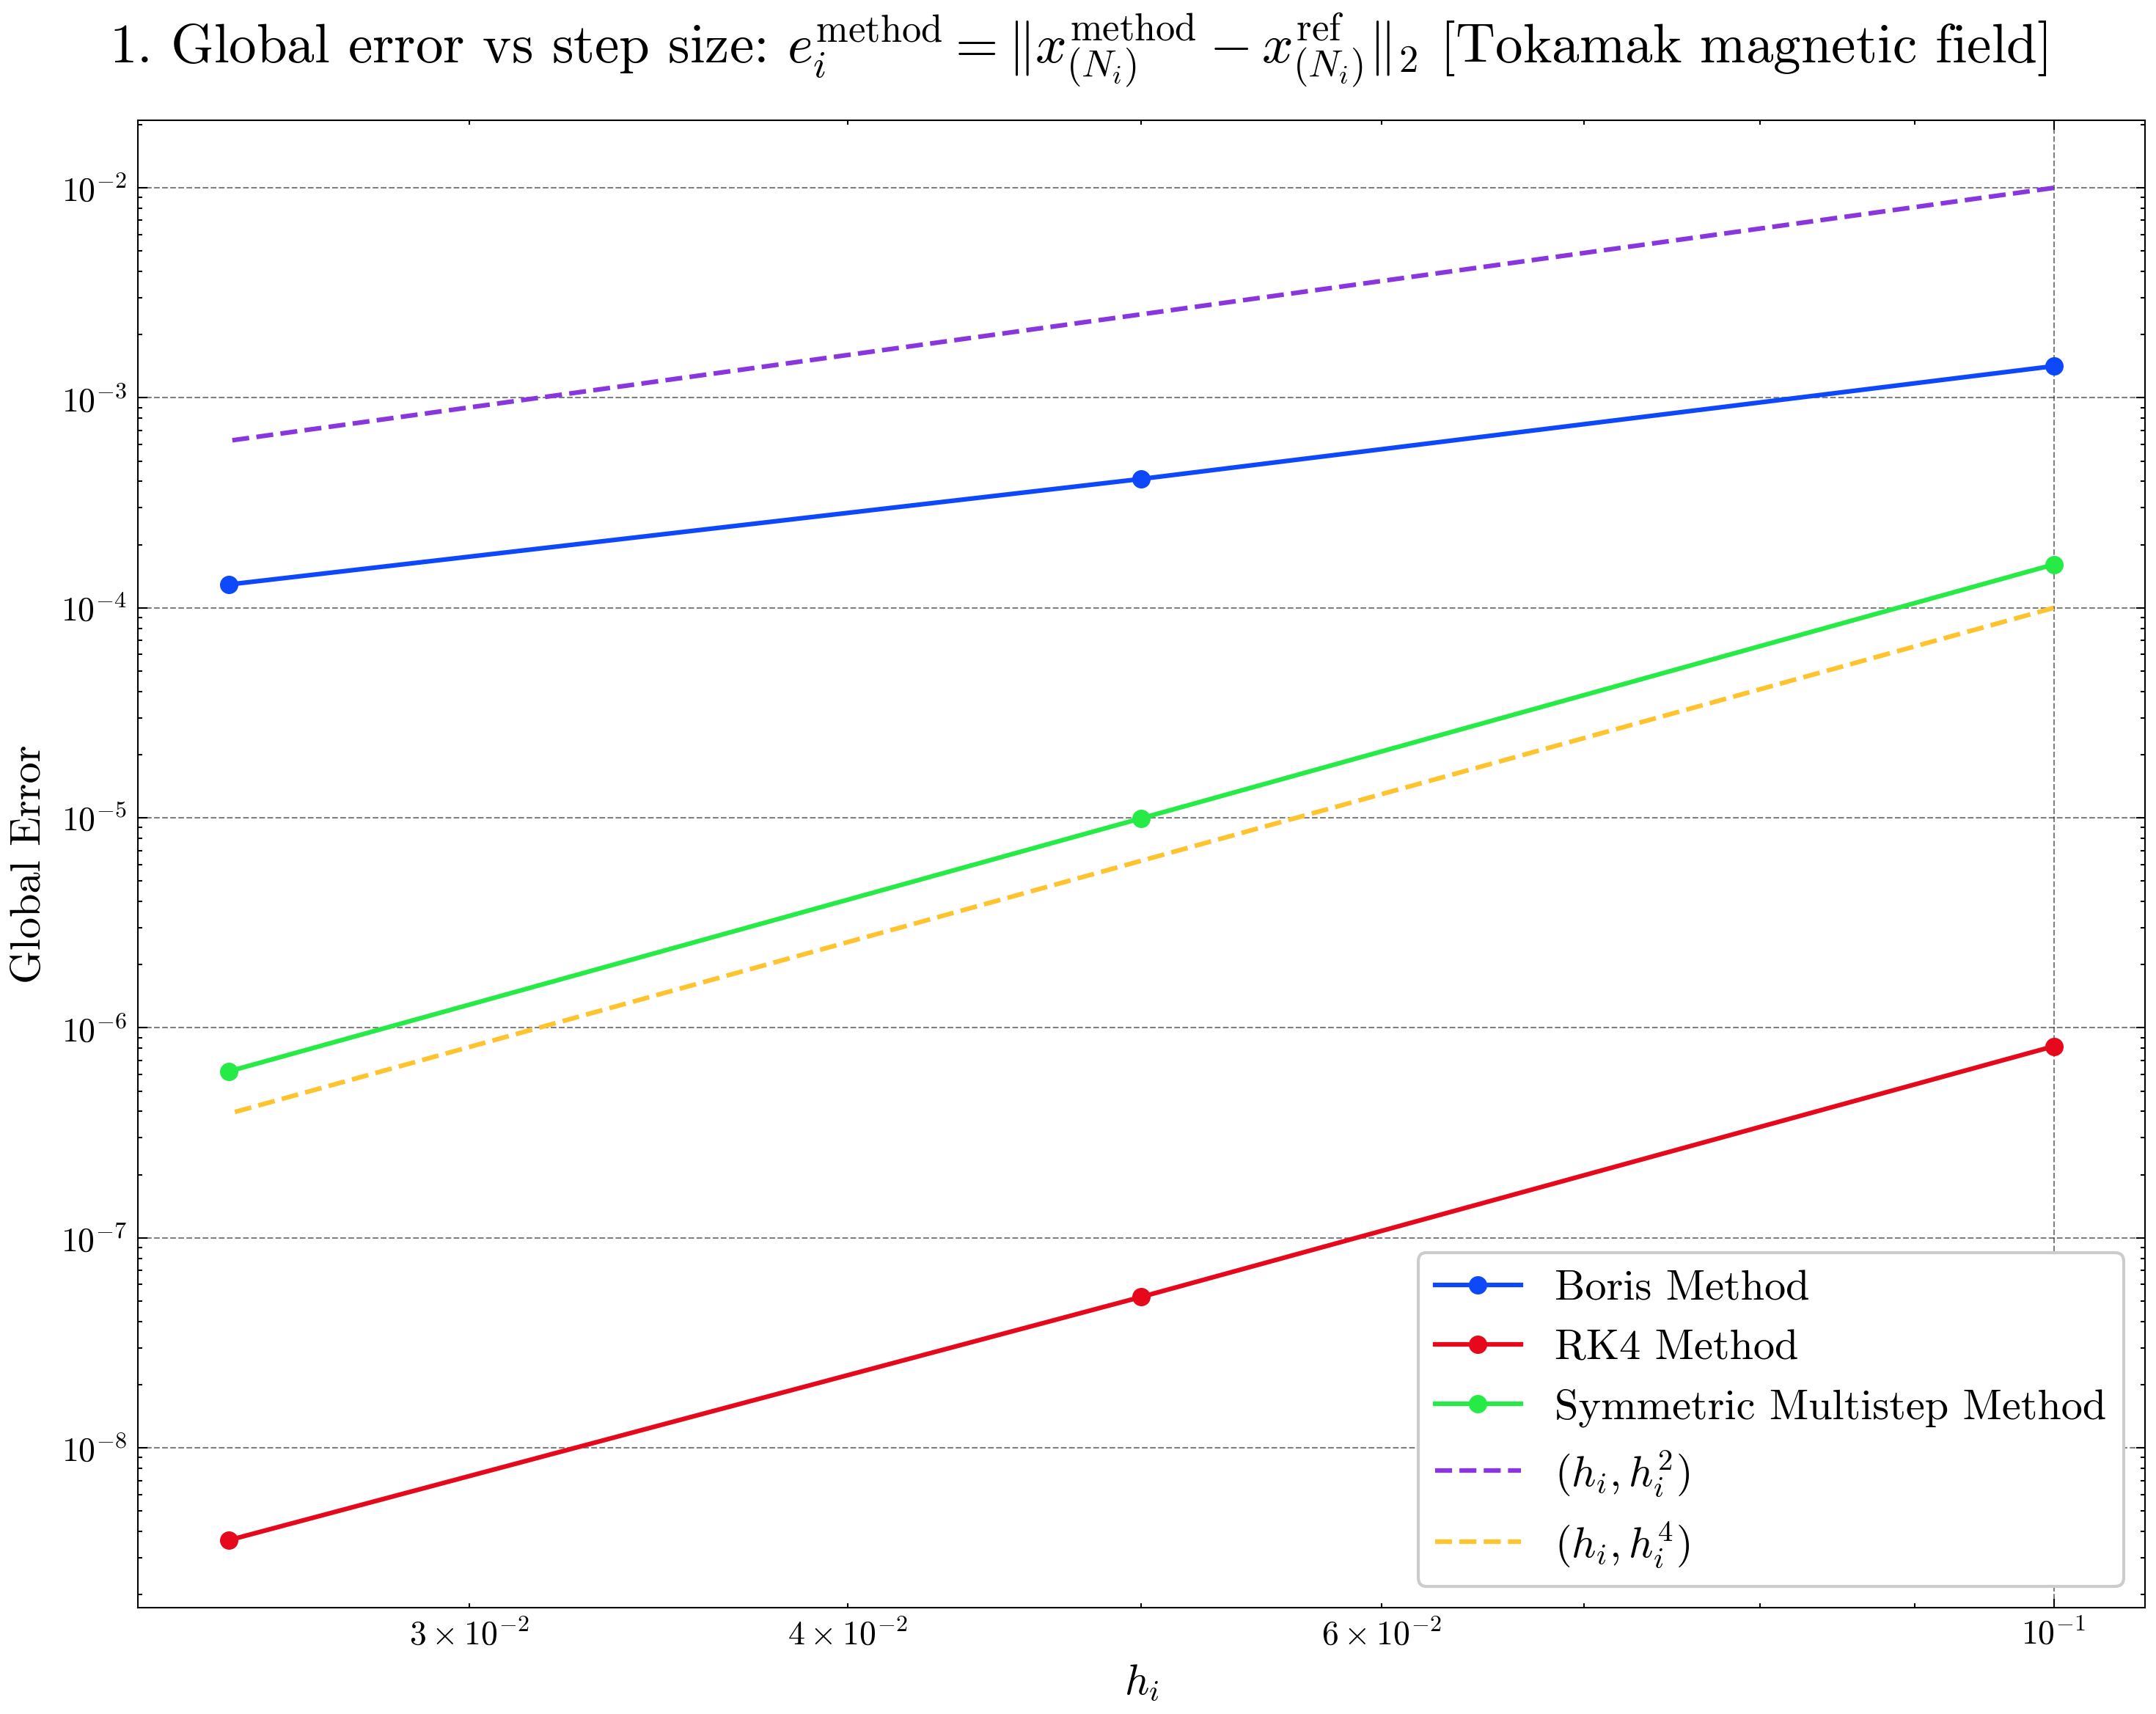

/var/folders/7m/vv_ld9cd50x2ywvm340_n1m40000gn/T/ipykernel_21842/3202822.py:141: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


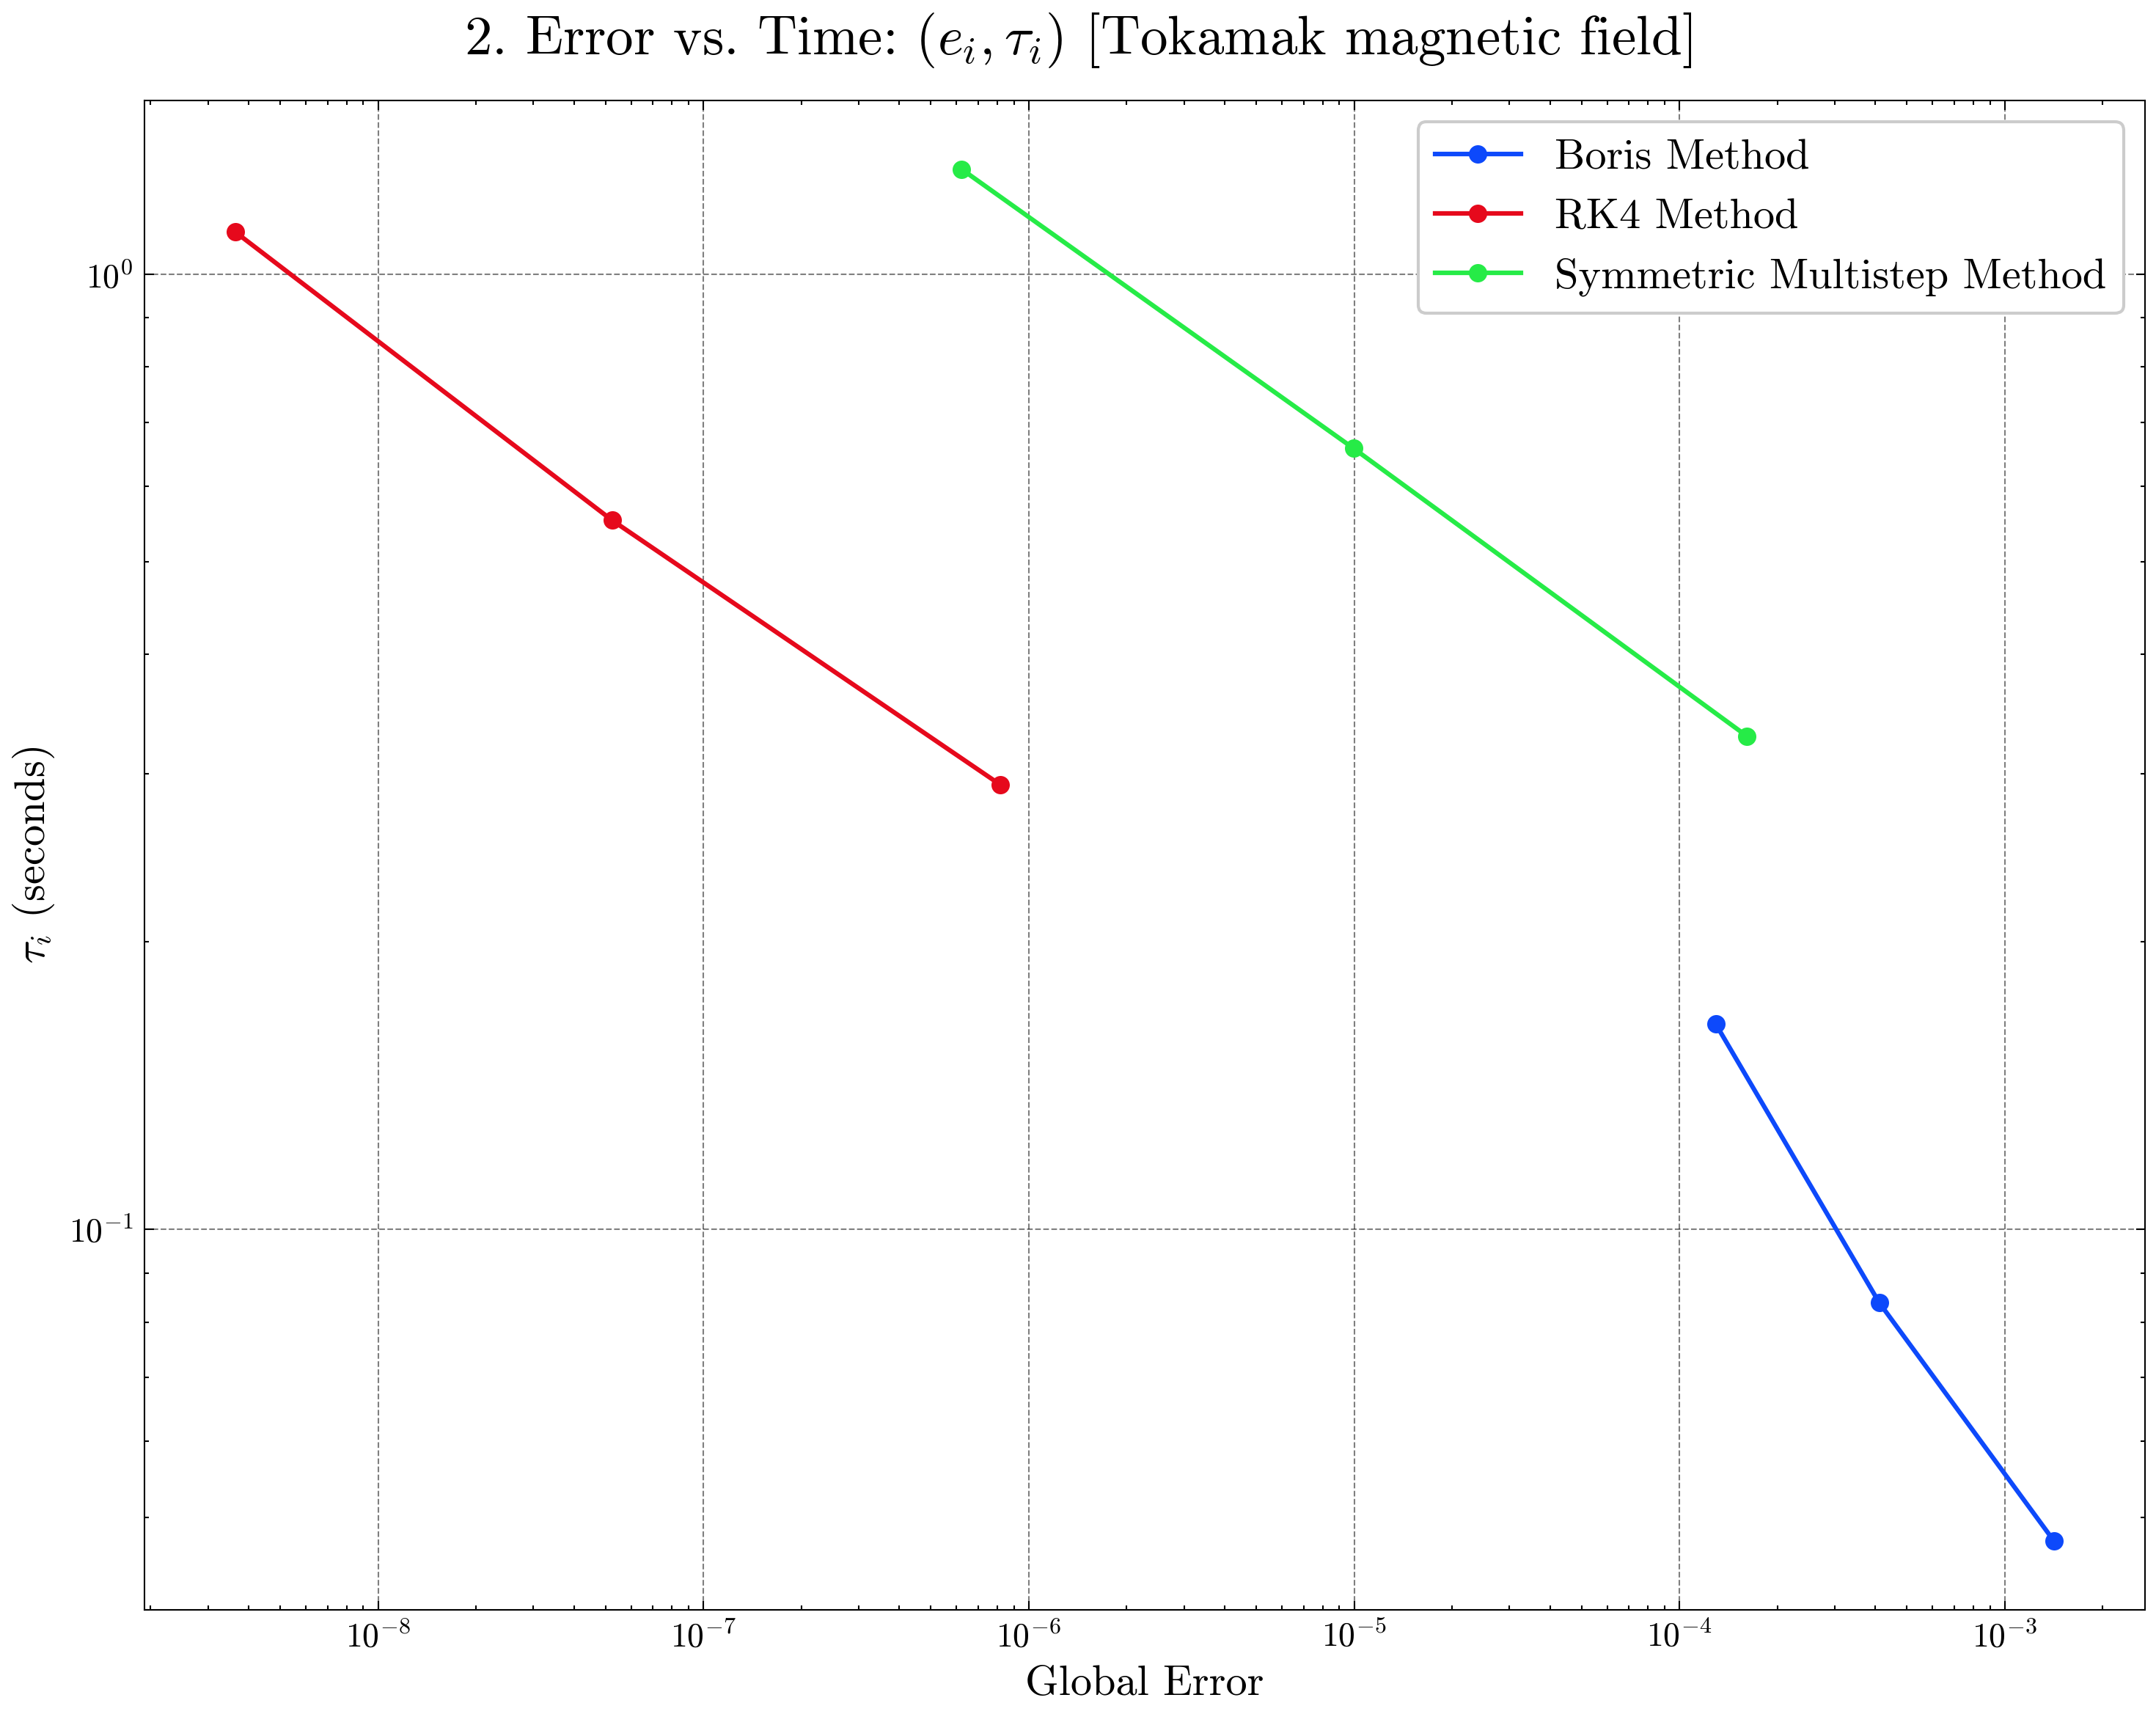

In [54]:
global_errors_boris_Tokamak = []
times_boris_Tokamak = []
global_errors_RK4_Tokamak = []
times_RK4_Tokamak = []
global_errors_MS_Tokamak = []
times_MS_Tokamak = []

# compute for each step size
for h_i in step_sizes:
    reference_solution_Tokamak_b = reference_solution(
        ic_Tokamak,
        A=A_Tokamak,
        B=B_Tokamak,
        gradU=gradU_Tokamak,
        h=h_i,
        t_start=0,
        t_end=Tb,
    )
    xB_reference_Tokamak = np.transpose(reference_solution_Tokamak_b.y[:3, :])
    vB_reference_Tokamak = np.transpose(reference_solution_Tokamak_b.y[3:, :])

    # Boris
    start_time = time.perf_counter()
    xB_boris_Tokamak, vB_boris_Tokamak = boris_method(
        ic=ic_Tokamak,
        t_start=0,
        t_end=Tb,
        h=h_i,
        U=U_Tokamak,
        B=B_Tokamak,
        A=A_Tokamak,
        gradU=gradU_Tokamak,
    )
    times_boris_Tokamak.append(time.perf_counter() - start_time)
    vB_boris_Tokamak = v_integer_steps(vB_boris_Tokamak)
    xB_boris_Tokamak = xB_boris_Tokamak[:-1, :]

    # RK4
    start_time = time.perf_counter()
    xB_RK4_Tokamak, vB_RK4_Tokamak = RK4_solver(
        h=h_i,
        B=B_Tokamak,
        gradU=gradU_Tokamak,
        ic=ic_Tokamak,
        t_start=0,
        t_end=Tb,
    )
    times_RK4_Tokamak.append(time.perf_counter() - start_time)

    # MS
    start_time = time.perf_counter()
    xB_MS_Tokamak, vB_MS_Tokamak = multistep_iterate(
        h=h_i,
        B=B_Tokamak,
        A=A_Tokamak,
        A_jac=Jacobian_A_Tokamak,
        gradU=gradU_Tokamak,
        ic=ic_Tokamak,
        t_start=0,
        t_end=Tb,
    )
    times_MS_Tokamak.append(time.perf_counter() - start_time)

    global_errors_boris_Tokamak.append(
        np.linalg.norm(xB_boris_Tokamak[-1] - xB_reference_Tokamak[-1, :], 2)
    )
    global_errors_RK4_Tokamak.append(
        np.linalg.norm(xB_RK4_Tokamak[-1] - xB_reference_Tokamak[-1, :], 2)
    )
    global_errors_MS_Tokamak.append(
        np.linalg.norm(xB_MS_Tokamak[-1] - xB_reference_Tokamak[-1, :], 2)
    )

# Figure 1: Global error vs step size
fig1, ax1 = plt.subplots(1, 1, figsize=(10, 8))
fig1.suptitle(
    r"1. Global error vs step size: "
    r"$e_i^{\mathrm{method}} = \| x_{(N_i)}^{\mathrm{method}} - x_{(N_i)}^{\mathrm{ref}} \|_2$ "
    r"[Tokamak magnetic field]"
)
ax1.loglog(
    step_sizes,
    global_errors_boris_Tokamak,
    "o-",
    label="Boris Method",
)
ax1.loglog(
    step_sizes,
    global_errors_RK4_Tokamak,
    "o-",
    label="RK4 Method",
)
ax1.loglog(
    step_sizes,
    global_errors_MS_Tokamak,
    "o-",
    label="Symmetric Multistep Method",
)
ax1.loglog(
    step_sizes,
    np.array(step_sizes) ** 2,
    "--",
    label=r"$(h_i, h_i^2)$",
)
ax1.loglog(
    step_sizes,
    np.array(step_sizes) ** 4,
    "--",
    label=r"$(h_i, h_i^4)$",
)
ax1.set_xlabel(r"$h_i$")
ax1.set_ylabel("Global Error")
ax1.legend()
plt.tight_layout()
plt.show()

# Figure 2: Work-precision (error vs computation time)
fig2, ax2 = plt.subplots(1, 1, figsize=(10, 8))
fig2.suptitle(r"2. Error vs. Time: $(e_i, \tau_i)$ [Tokamak magnetic field]")
ax2.loglog(
    global_errors_boris_Tokamak,
    times_boris_Tokamak,
    "o-",
    label="Boris Method",
)
ax2.loglog(
    global_errors_RK4_Tokamak,
    times_RK4_Tokamak,
    "o-",
    label="RK4 Method",
)
ax2.loglog(
    global_errors_MS_Tokamak,
    times_MS_Tokamak,
    "o-",
    label="Symmetric Multistep Method",
)
ax2.set_xlabel("Global Error")
ax2.set_ylabel(r"$\tau_i$ (seconds)")
ax2.legend()
plt.tight_layout()
plt.show()

#### Discussion – Order verification and work–precision diagrams

For the Tokamak system, the results are essentially the same as for the 2D charged particle. All methods show their expected convergence orders, with Boris being second-order and both RK4 and the Symmetric Multistep method showing fourth-order accuracy. The work–precision diagram also follows the same trend: Boris is fastest but least accurate, RK4 is most accurate but more expensive, and the Symmetric Multistep method lies between them. Overall, the efficiency and accuracy results are consistent with what was observed in the 2D case and match the expected theoretical behaviour.


## $\text{C. Exploratory exercise}$

### $\text{Reproducing Fig. 6 in [3].}$

In [33]:
hc = np.pi / 10
Tc = 5e5 * hc
num_steps_c = int(Tc / hc)
t_c = np.linspace(0, Tc, num_steps_c + 1)

In [34]:
iv_xC = np.array([1.05, 0.0, 0.0])
iv_vC = np.array([0, 4.816e-4, -2.059e-3])
iv_vC_transit = np.array([0, 2 * 4.816e-4, -2.059e-3])

ic_banana = np.hstack((iv_xC, iv_vC))
ic_transit = np.hstack((iv_xC, iv_vC_transit))

xC_boris_banana, vC_boris_banana = boris_method(
    ic=ic_banana,
    t_start=0,
    t_end=Tc,
    h=hc,
    U=U_Tokamak,
    B=B_Tokamak,
    A=A_Tokamak,
    gradU=gradU_Tokamak,
)
vC_boris_banana = v_integer_steps(vC_boris_banana)
xC_boris_banana = xC_boris_banana[:-1, :]
t_boris_banana = t_c[:-1]

xC_boris_transit, vC_boris_transit = boris_method(
    ic=ic_transit,
    t_start=0,
    t_end=Tc,
    h=hc,
    U=U_Tokamak,
    B=B_Tokamak,
    A=A_Tokamak,
    gradU=gradU_Tokamak,
)
vC_boris_transit = v_integer_steps(vC_boris_transit)
xC_boris_transit = xC_boris_transit[:-1, :]
t_boris_transit = t_c[:-1]

xC_RK4_banana, vC_RK4_banana = RK4_solver(
    h=hc,
    B=B_Tokamak,
    gradU=gradU_Tokamak,
    ic=ic_banana,
    t_start=0,
    t_end=Tc,
)

xC_RK4_transit, vC_RK4_transit = RK4_solver(
    h=hc,
    B=B_Tokamak,
    gradU=gradU_Tokamak,
    ic=ic_transit,
    t_start=0,
    t_end=Tc,
)

RK4 Method: 100%|██████████| 499999/499999 [00:13<00:00, 36649.14it/s]


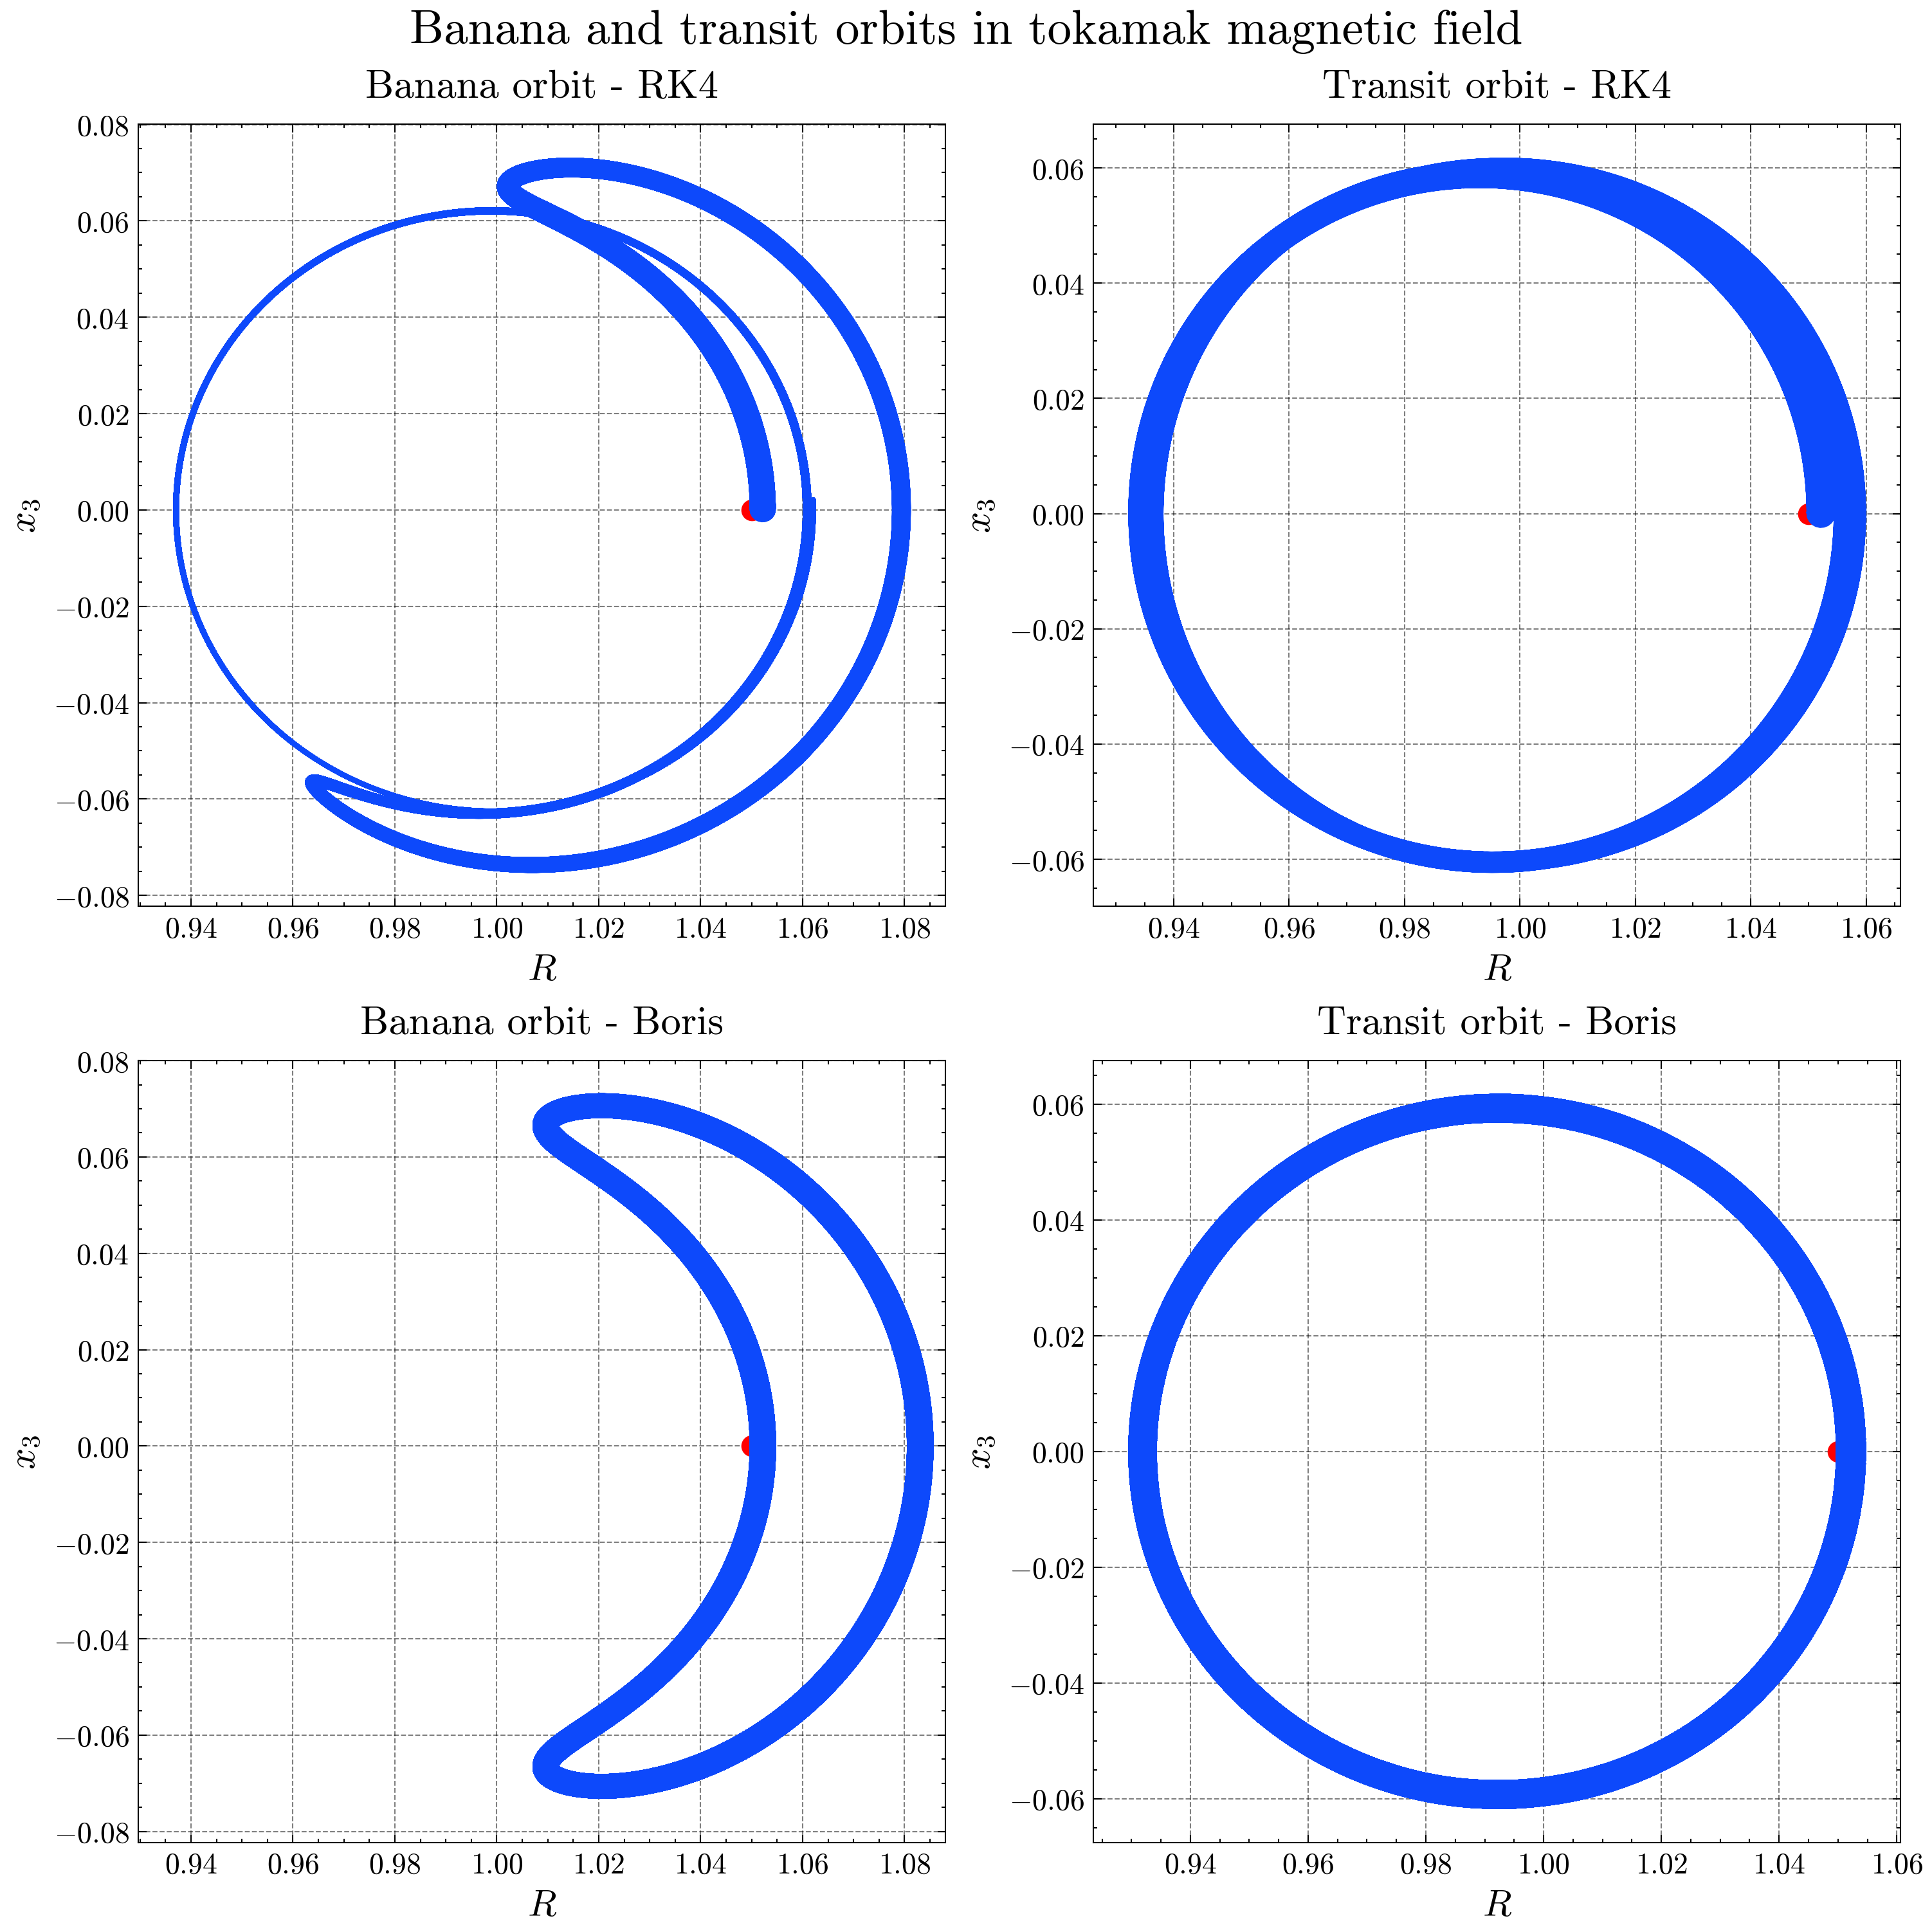

In [55]:
R_boris_banana = np.sqrt(
    np.square(xC_boris_banana[:, 0]) + np.square(xC_boris_banana[:, 1])
)
x3_boris_banana = xC_boris_banana[:, 2]

R_boris_transit = np.sqrt(
    np.square(xC_boris_transit[:, 0]) + np.square(xC_boris_transit[:, 1])
)
x3_boris_transit = xC_boris_transit[:, 2]

R_RK4_banana = np.sqrt(np.square(xC_RK4_banana[:, 0]) + np.square(xC_RK4_banana[:, 1]))
x3_RK4_banana = xC_RK4_banana[:, 2]

R_RK4_transit = np.sqrt(
    np.square(xC_RK4_transit[:, 0]) + np.square(xC_RK4_transit[:, 1])
)
x3_RK4_transit = xC_RK4_transit[:, 2]

fig, axs = plt.subplots(2, 2, figsize=(10, 10))
fig.suptitle(r"Banana and transit orbits in tokamak magnetic field")
# Banana orbit - RK4
axs[0, 0].scatter(
    R_RK4_banana[0],
    x3_RK4_banana[0],
    color="red",
    s=50,
    label="Start",
)
axs[0, 0].plot(R_RK4_banana, x3_RK4_banana)
axs[0, 0].set_title("Banana orbit - RK4")
axs[0, 0].set_xlabel(r"$R$")
axs[0, 0].set_ylabel(r"$x_3$")
axs[0, 0].set_aspect("auto")
# Transit orbit - RK4
axs[0, 1].scatter(
    R_RK4_transit[0],
    x3_RK4_transit[0],
    color="red",
    s=50,
    label="Start",
)
axs[0, 1].plot(R_RK4_transit, x3_RK4_transit)
axs[0, 1].set_title("Transit orbit - RK4")
axs[0, 1].set_xlabel(r"$R$")
axs[0, 1].set_ylabel(r"$x_3$")
axs[0, 1].set_aspect("auto")
# Banana orbit - Boris
axs[1, 0].scatter(
    R_boris_banana[0],
    x3_boris_banana[0],
    color="red",
    s=50,
    label="Start",
)
axs[1, 0].plot(R_boris_banana, x3_boris_banana)
axs[1, 0].set_title("Banana orbit - Boris")
axs[1, 0].set_xlabel(r"$R$")
axs[1, 0].set_ylabel(r"$x_3$")
axs[1, 0].set_xlim(axs[0, 0].get_xlim())
axs[1, 0].set_ylim(axs[0, 0].get_ylim())
axs[1, 0].set_aspect("auto")
# Transit orbit - Boris
axs[1, 1].scatter(
    R_boris_transit[0],
    x3_boris_transit[0],
    color="red",
    s=50,
    label="Start",
)
axs[1, 1].plot(R_boris_transit, x3_boris_transit)
axs[1, 1].set_title("Transit orbit - Boris")
axs[1, 1].set_xlabel(r"$R$")
axs[1, 1].set_ylabel(r"$x_3$")
axs[1, 1].set_aspect("auto")
plt.show()

#### Discussion
We are using a step size $h=\frac{\pi}{10} \approx 0.314$, which is larger than what we were using in the previous exercises.
The figure above, reproducing the one found in [3], shows how RK4 fails to maintain the correct orbit for larger step sizes.
The Boris method on the other hand, still produces the correct one.


### $\text{Implicit midpoint method}$

In [36]:
def IM_step(h, x_n, v_n, f, B, gradU, tol=1e-10, max_iter=20):
    x_next, v_next = x_n.copy(), v_n.copy()

    # Fixed-point iteration to find (x_{n+1}, v_{n+1})
    for _ in range(max_iter):
        x_mid = 0.5 * (x_n + x_next)
        v_mid = 0.5 * (v_n + v_next)
        f_mid = f(x_mid, v_mid, B, gradU)
        x_new = x_n + h * v_mid
        v_new = v_n + h * f_mid
        if (
            np.linalg.norm(x_new - x_next) < tol
            and np.linalg.norm(v_new - v_next) < tol
        ):
            break
        x_next, v_next = x_new, v_new
    return x_next, v_next


def IM_solver(h, B, gradU, ic, t_start, t_end):
    num_steps = int((t_end - t_start) / h) + 1
    x = np.zeros(shape=(num_steps, 3))
    v = np.zeros(shape=(num_steps, 3))
    x[0] = ic[:3]
    v[0] = ic[3:]

    with tqdm(
        total=num_steps - 1,
        desc="Implicit Midpoint Method",
        bar_format="{l_bar}{bar}| {n_fmt}/{total_fmt} [{elapsed}<{remaining}, {rate_fmt}]",
    ) as pbar:
        for i in range(num_steps - 1):
            x[i + 1], v[i + 1] = IM_step(h, x[i], v[i], f, B, gradU)
            pbar.update(1)

    return x, v


# Implicit Midpoint Method
x_IM_Tokamak, v_IM_Tokamak = IM_solver(
    h=h,
    B=B_Tokamak,
    gradU=gradU_Tokamak,
    ic=ic_Tokamak,
    t_start=0,
    t_end=T,
)

Implicit Midpoint Method: 100%|██████████| 1000000/1000000 [01:01<00:00, 16194.43it/s]


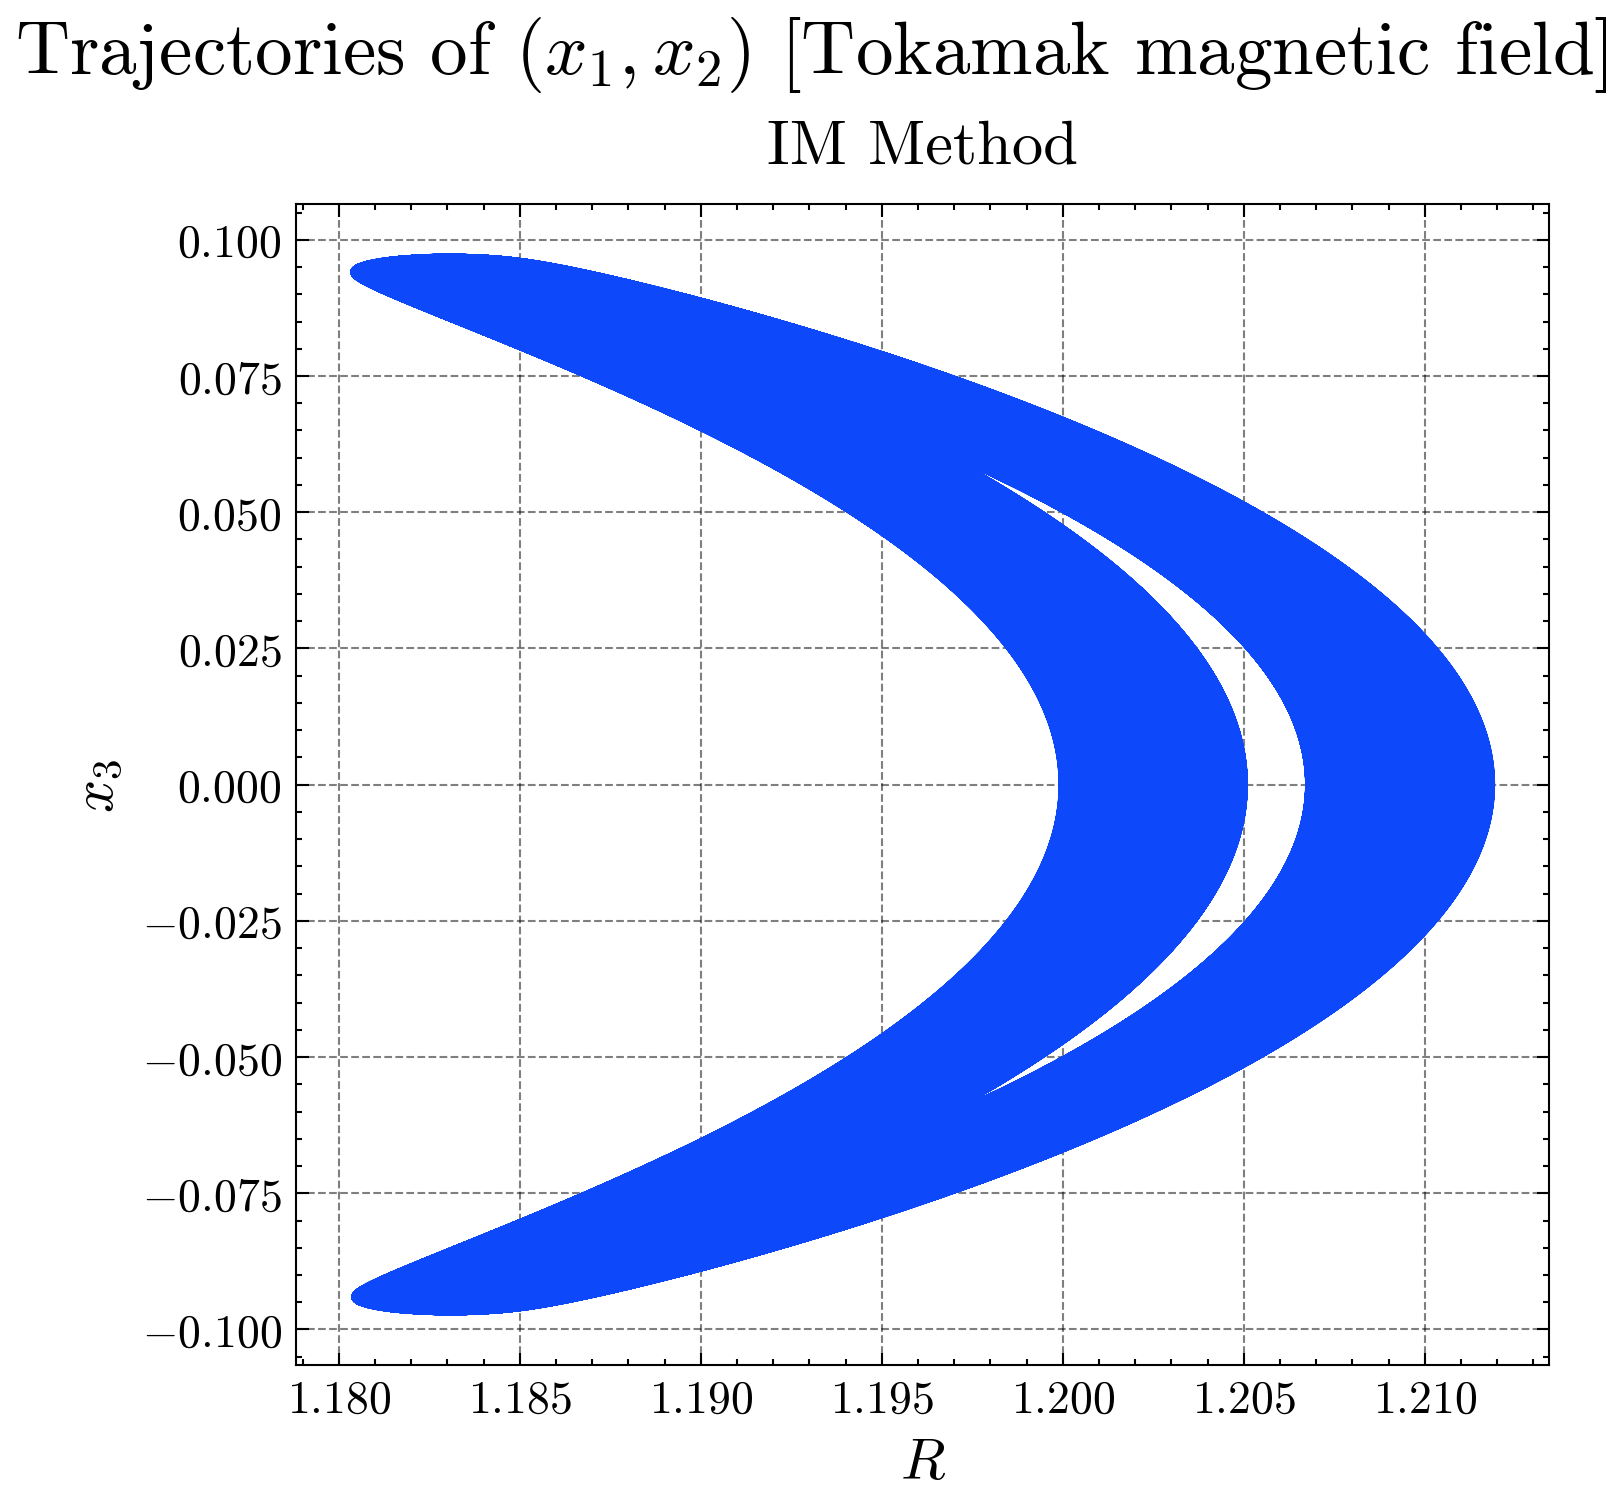

In [56]:
R_IM_Tokamak = np.sqrt(np.square(x_IM_Tokamak[:, 0]) + np.square(x_IM_Tokamak[:, 1]))
x3_IM_Tokamak = x_IM_Tokamak[:, 2]

fig, axs = plt.subplots(figsize=(5, 5))
fig.suptitle(r"Trajectories of $(x_1, x_2)$ [Tokamak magnetic field]")
axs.set_title("IM Method")
axs.plot(
    R_IM_Tokamak,
    x3_IM_Tokamak,
)
axs.set_xlabel(r"$R$")
axs.set_ylabel(r"$x_3$")
axs.set_aspect("auto")
plt.show()

#### Discussion
The implicit midpoint method also gives a correct banana orbit as shown in the figure above. However, the runtime is quite a bit slower than the other methods we have used, likely due to having to solve a nonlinear system using fixed-point iteration.

### $\text{Verifiying momentum conservation}$

We are using the formula for momentum given in $[2]$ $$M(x, v) = (v_1 + A_1(x)) x_2 - (v_2 + A_2(x)) x_1.$$ to see which methods conserve the momentum


In [38]:
def momentum(x, v, A):
    """
    Calculates the conserved momentum.
    """
    A_vec = A(x)

    return (v[0] + A_vec[0]) * x[1] - (v[1] + A_vec[1]) * x[0]


def momentum_error(initial_momentum, x_matrix, v_matrix, A_func):
    """Calculates the absolute error in momentum over time."""

    momentum_solution = np.zeros(x_matrix.shape[0])
    for i in range(x_matrix.shape[0]):
        momentum_solution[i] = momentum(x_matrix[i, :], v_matrix[i, :], A_func)

    initial_momentum_vec = np.empty(len(x_matrix))
    initial_momentum_vec.fill(initial_momentum)
    return np.abs(momentum_solution - initial_momentum)

/var/folders/7m/vv_ld9cd50x2ywvm340_n1m40000gn/T/ipykernel_21842/2886740006.py:49: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


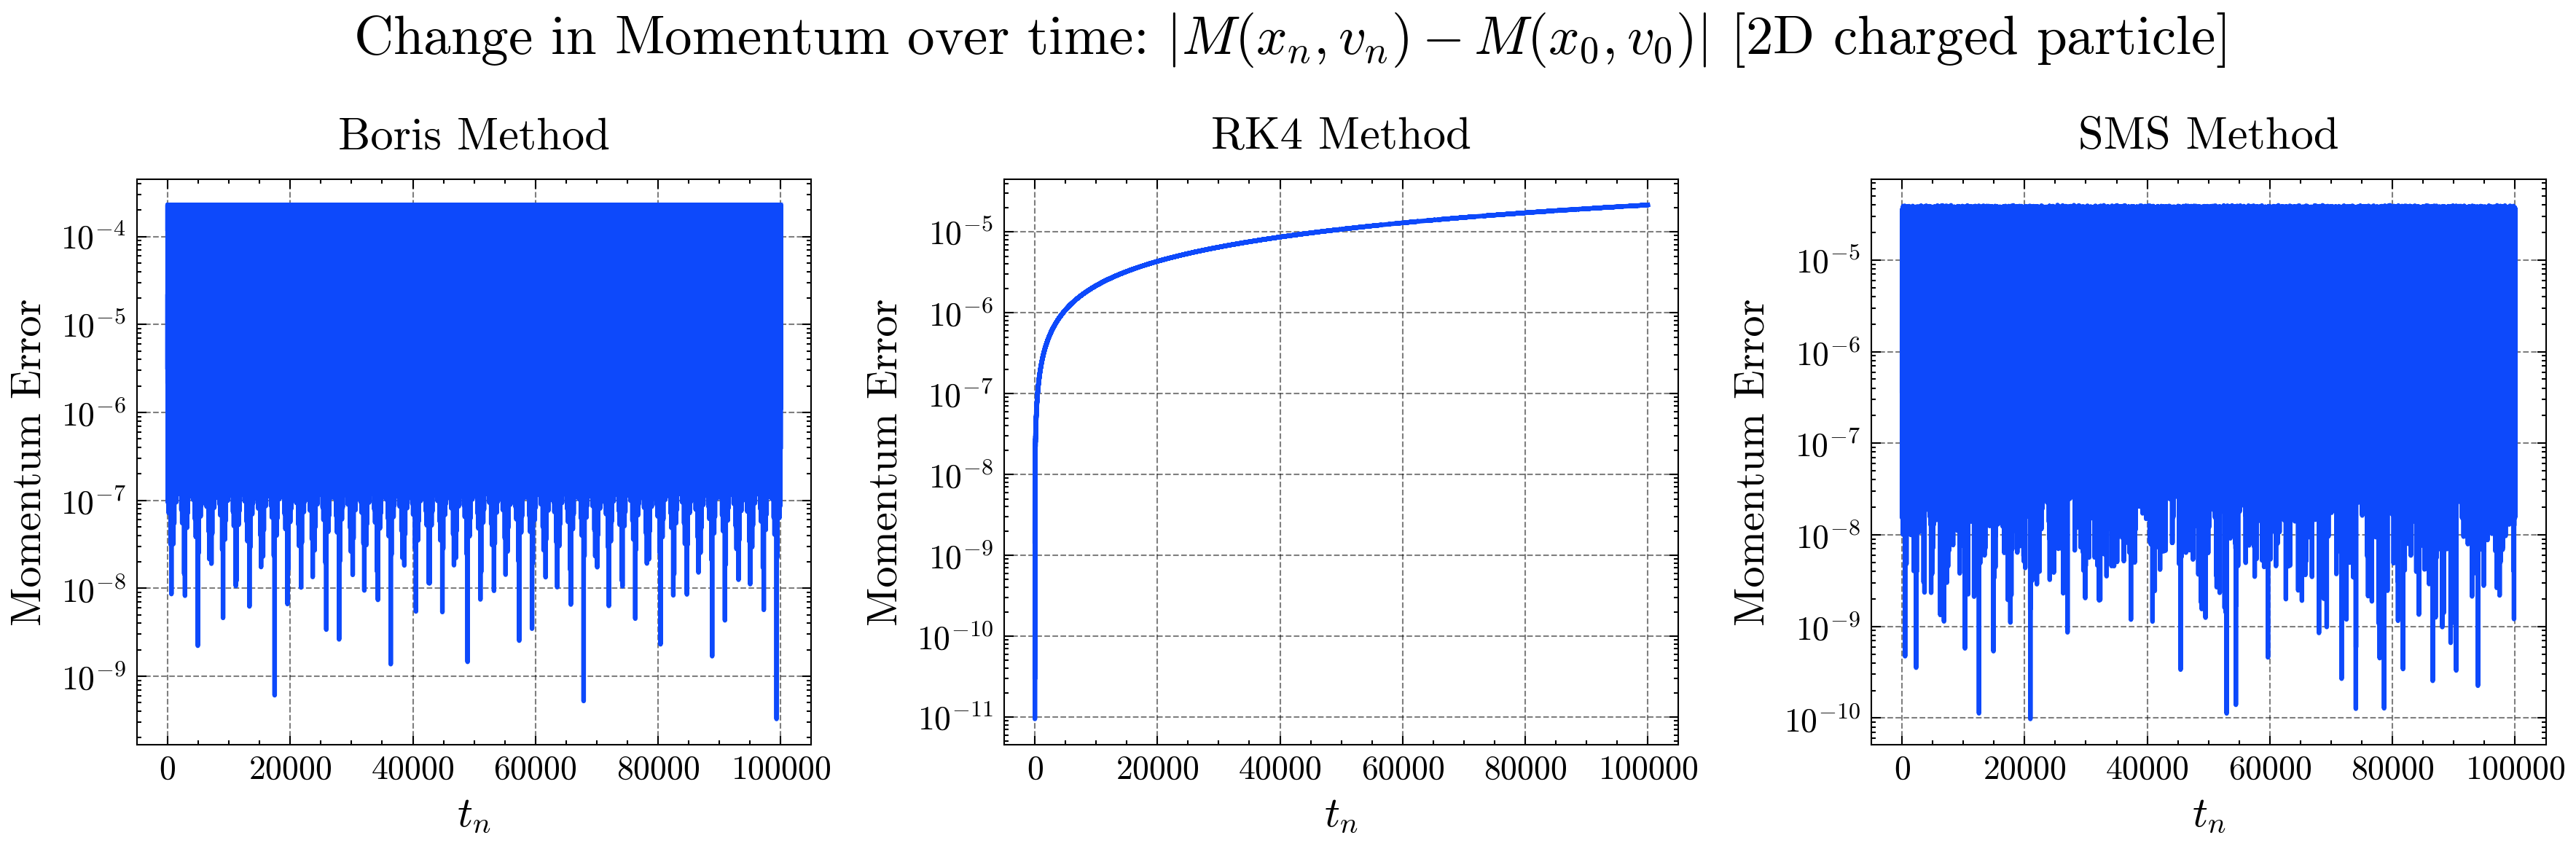

In [57]:
initial_momentum_2D = momentum(iv_x_2D, iv_v_2D, A_2D)
initial_momentum_Tokamak = momentum(iv_x_Tokamak, iv_v_Tokamak, A_Tokamak)


momentum_error_boris_2D = momentum_error(
    initial_momentum_2D, x_boris_2D, v_boris_2D, A_2D
)
momentum_error_RK4_2D = momentum_error(initial_momentum_2D, x_RK4_2D, v_RK4_2D, A_2D)
momentum_error_MS_2D = momentum_error(initial_momentum_2D, x_MS_2D, v_MS_2D, A_2D)

idx_2D = slice(2, -2)


fig, axs = plt.subplots(1, 3, figsize=(12, 4))
fig.suptitle(
    r"Change in Momentum over time: $|M(x_n, v_n) - M(x_0, v_0)|$ [2D charged particle]"
)

# Boris method
axs[0].semilogy(
    t_boris_2D[idx_2D],
    momentum_error_boris_2D[idx_2D],
)
axs[0].set_title("Boris Method")
axs[0].set_xlabel(r"$t_n$")
axs[0].set_ylabel(r"Momentum Error")
axs[0].set_aspect("auto")

# RK4
axs[1].semilogy(
    t[idx_2D],
    momentum_error_RK4_2D[idx_2D],
)
axs[1].set_title("RK4 Method")
axs[1].set_xlabel(r"$t_n$")
axs[1].set_ylabel(r"Momentum Error")
axs[1].set_aspect("auto")

# Fourth-order symmetric multistep method
axs[2].semilogy(
    t[idx_2D],
    momentum_error_MS_2D[idx_2D],
)
axs[2].set_title("SMS Method")
axs[2].set_xlabel(r"$t_n$")
axs[2].set_ylabel(r"Momentum Error")
axs[2].set_aspect("auto")

plt.tight_layout()
plt.show()

##### Discussion
For the Boris method we can that the momentum error remains bounded below $10^{-4}$ and shows a stable pattern over the entire $T=10^5$ time interval.
Similar to the Boris method, the error for the symmetric multistep method is bounded and remains below approximately $\times 10^{-5}$. This confirms the  tability properties of the $s$-stable symmetric multistep method, as stated in Theorem 3.3 of [2].
For the RK4 method the momentum error exhibits a growth, increasing from $10^{-11}$ to approximately $10^{-5}$ over the simulation time. This continuous growth, in contrast to the bounded errors of the other two methods, demonstrates that RK4, being a non-geometric method, fails to preserve this physical invariant over long times.


/var/folders/7m/vv_ld9cd50x2ywvm340_n1m40000gn/T/ipykernel_21842/3023126432.py:46: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


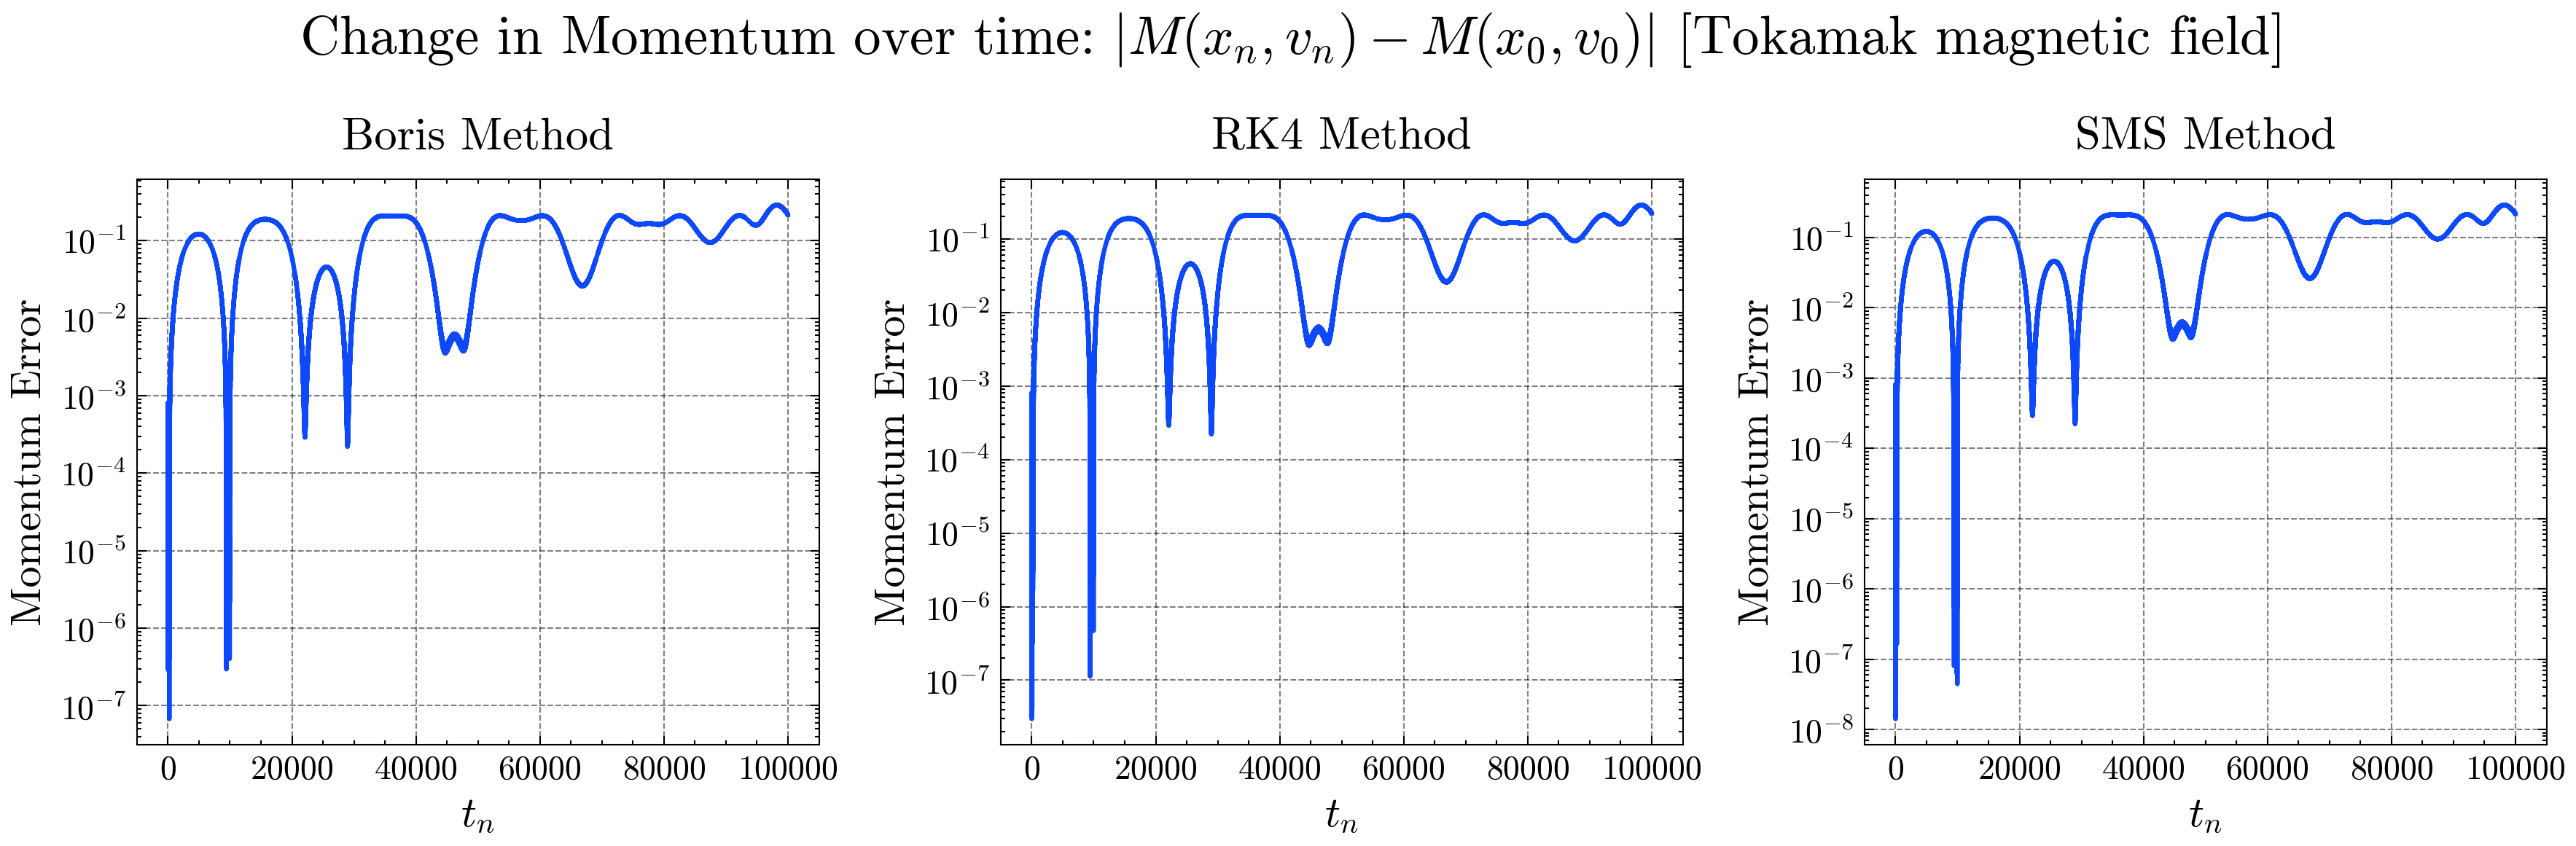

In [59]:
# Calculate momentum errors for Tokamak magnetic field system
momentum_error_boris_Tokamak = momentum_error(
    initial_momentum_Tokamak, x_boris_Tokamak, v_boris_Tokamak, A_Tokamak
)
momentum_error_RK4_Tokamak = momentum_error(
    initial_momentum_Tokamak, x_RK4_Tokamak, v_RK4_Tokamak, A_Tokamak
)
momentum_error_MS_Tokamak = momentum_error(
    initial_momentum_Tokamak, x_MS_Tokamak, v_MS_Tokamak, A_Tokamak
)

idx_Tokamak = slice(2, -2)

fig, axs = plt.subplots(1, 3, figsize=(12, 4))
fig.suptitle(
    r"Change in Momentum over time: $|M(x_n, v_n) - M(x_0, v_0)|$ [Tokamak magnetic field]"
)

# Boris method
axs[0].semilogy(
    t_boris_Tokamak[idx_Tokamak],
    momentum_error_boris_Tokamak[idx_Tokamak],
)
axs[0].set_title("Boris Method")
axs[0].set_xlabel(r"$t_n$")
axs[0].set_ylabel(r"Momentum Error")
axs[0].set_aspect("auto")

# RK4
axs[1].semilogy(
    t[idx_Tokamak],
    momentum_error_RK4_Tokamak[idx_Tokamak],
)
axs[1].set_title("RK4 Method")
axs[1].set_xlabel(r"$t_n$")
axs[1].set_ylabel(r"Momentum Error")
axs[1].set_aspect("auto")

# Fourth-order symmetric multistep method
axs[2].semilogy(t[idx_Tokamak], momentum_error_MS_Tokamak[idx_Tokamak])
axs[2].set_title("SMS Method")
axs[2].set_xlabel(r"$t_n$")
axs[2].set_ylabel(r"Momentum Error")
axs[2].set_aspect("auto")

plt.tight_layout()
plt.show()

The momentum error for the Tokamak test case behaves differently from the previous experiment. All three methods produce curves that are almost identical, with the same oscillatory pattern and with peaks and minima occurring at the same time steps. This is unexpected, since the implemented methods have different stability properties and typically show different long-time behaviour.

We have checked the implementation: each method computes its own trajectory, and `momentum_error(...)` is evaluated separately for each set of $((x_n, v_n))$. There is no shared data or accidental reuse of values between the methods, so we are not really sure why this happens.